# COMP40731 Artificial Cognitive Systems
### Student name: Bhagyesh Chaudhari
### Student Id: N1218683
### Group Id: ACS_5
**Note:** Only if you worked in a group
### Group member id:
**Note:** Only if you worked in a group

### Markdown language support
Check [here](https://www.markdownguide.org/extended-syntax/) to find more details about markdown


### Add a diagram of your architecture

<ADD DIAGRAM HERE>


# Notes

### JSON for Configuration Flexibility: 
JSON files must be utilised to enable flexible configuration of SNN network parameters, storing crucial details such as layer sizes, learning rates, and hyperparameters.

### HDF5 Storage for Encoded Signal:  
Separate HDF5 files must be implemented to store the encoded signal before and after exposure to noise. The structure, datasets, and relevant metadata must be clearly documented.

### NPY Storage for SNN Weights: 
SNN weights must be stored in an NPY file, including weights for each network layer. Clear explanations and comments within the Jupyter Notebook regarding the organisation and structure of the NPY file are required.

### AI Ethics Integration: 
AI ethics by design principles must be integrated into the SNN implementation. Implement steps to identify and mitigate algorithmic biases. 

### Spiking Records and Multimeters Integration:

    Utilise spiking records and multimeters within the SNN architecture to record spike events and measure action potentials of decoding neurons.
    Use spike recorders, capturing temporal patterns and relevant information during the encoding, decoding, and learning processes.
    Use multimeters to measure the action potentials of decoding neurons, providing valuable insights into the dynamics and responsiveness of the network.
    Integrate visualisations or plots within the Jupyter Notebook to showcase the recorded spiking events and action potentials, aiding in a comprehensive analysis of the SNN's behaviour and performance.
    
### Intercalated Training and Testing with Synaptic Switching:

    Implement an intercalated training approach where supervised learning is used for a specified number of epochs, followed by testing using static synapses for a single epoch.
    During training epochs, utilise supervised learning to enhance the SNN's performance and optimise decoding capabilities.
    Implement a mechanism to switch synapses to a static configuration during testing, allowing for the assessment of the network's generalisation and stability.
    Periodically store the SNN weights before switching to static synapses to preserve the learned information and facilitate analysis.
    Document and discuss the impact of this intercalated training and testing approach on the SNN's performance, emphasising improvements achieved through supervised learning and the network's ability to generalise with static synapses.


## Import section
Import all the libraies that you need

**Reading the Video**


In [21]:
import cv2

# providing the file path
video_path = '/home/ntu-user/PycharmProjects/COMP40731---ACS---CWK---N1218683/COMP40731_video.mp4/COMP40731_video.mp4'

# open the video capture
cap = cv2.VideoCapture(video_path)
# checking the video capture is successfully opened
if not cap.isOpened():
    print(f"Error: Update to open the video at path {video_path}")
else:
    print("press'q' to stop the video")

    # read and display each frame from the video
    while True:
        ret, frame = cap.read()

        # Break the loop if video has ended
        if not ret:
            break
        # Break the loop if 'q'is pressed
        if cv2.waitKey(25) & 0xFF == ord('q'):
            break
    # Released the video capture object
    cap.release()
    # Closed all windows
    cv2.destroyAllWindows()






press'q' to stop the video


**Seprated Image and Audio file from Video**

In [23]:
import cv2
import os
from pydub import AudioSegment

cap = cv2.VideoCapture('/home/ntu-user/PycharmProjects/COMP40731---ACS---CWK---N1218683/COMP40731_video.mp4/COMP40731_video.mp4')

if not os.path.exists('frames'):
    os.makedirs('frames')

frame_count = 0
while (cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    cv2.imwrite(f'frames/frame_{frame_count:03d}.png', frame)
    frame_count += 1

audio = AudioSegment.from_file('/home/ntu-user/PycharmProjects/COMP40731---ACS---CWK---N1218683/COMP40731_video.mp4/COMP40731_video.mp4')
audio.export('audio.mp3', format= 'mp3')


cap.release()
cv2.destroyAllWindows()


#### layer 1 (encoding layer): How many populations of neurons? How many neurons per populations? Which neuron models were used? What are the connectivity types? Provide a table with all the parameterisations for the neurons and synapses
The encoding layer should independently encode both image and sound information using these channels.
Use  one of the following neuron models:

    iaf_psc_exp – Leaky integrate-and-fire neuron model with exponential PSCs
    iaf_psc_alpha – Leaky integrate-and-fire model with alpha-shaped input currents
    izhikevich – Izhikevich neuron model
    mat2_psc_exp – Non-resetting leaky integrate-and-fire neuron model with exponential PSCs and adaptive threshold
    parrot_neuron_ps – Neuron that repeats incoming spikes - precise spike timing version


##### Neurons
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


##### Synapses
| parameter | Description    | value or range       | IS units | 
| --------- | -------------  |----------------------| -------- |
| 'delay'   |snyaptic delay  | typical value(eg.1ms)|  ms      |
| --------- | -------------  |----------------------|----------|
| 'weight'  | snyaptic weight|typically uniform     |          |


###### Connectivity details
        | parameter   | Description                                        | value or range        | IS units | 
        | ------------| ---------------------------------------------------|-----------------------| -------- |
        | Connectivity| Type of connectivity between neurons and recorder  |One-to-One (All-to-All)|          |


###### Does the architecture changes during the training and inference phases? If you answer yes, explain why.
The architecture does not change during the training and inference phases. The same encoding layer is used for both phases. This is because the encoding layer's purpose is to independently encode both image and sound information using the provided color channels. The neuronal and synaptic parameters remain the same throughout the process as they are configured based on the characteristics of the neural network and the input data, not the phase of operation.



# Image Encoding


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.6.0
 Built: Nov 16 2023 09:28:21

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

Reading image frame_021...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:45<00:00, 1314.65it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:45<00:00, 1317.47it/
Setting currents for Red channel: 100%|▉| 59954/60000 [00:41<00:00, 1445.56it/s]

Simulating for frame_021
Simulation completed for frame_021
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


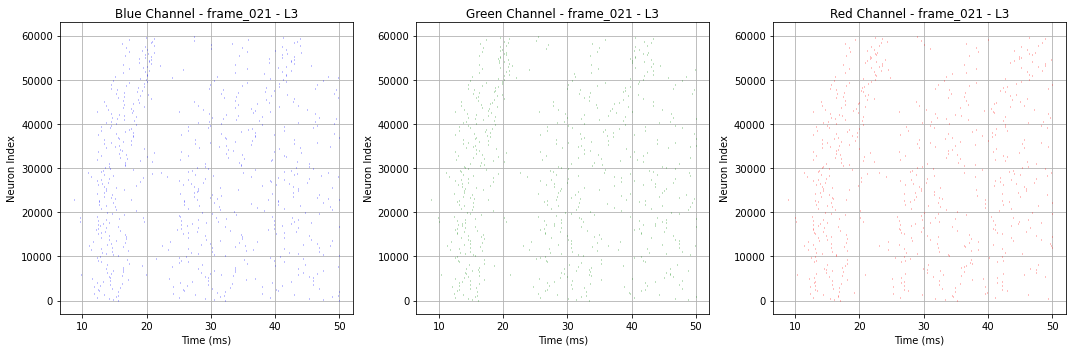

Setting currents for Red channel: 100%|█| 60000/60000 [00:59<00:00, 1014.67it/s]


Reading image frame_022...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:44<00:00, 1359.84it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:43<00:00, 1388.89it/
Setting currents for Red channel: 100%|▉| 59993/60000 [00:41<00:00, 1441.80it/s]

Simulating for frame_022
Simulation completed for frame_022
Subtracting the propagation delay: 13.0 ms.


Setting currents for Red channel: 100%|█| 60000/60000 [00:52<00:00, 1441.80it/s]

Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


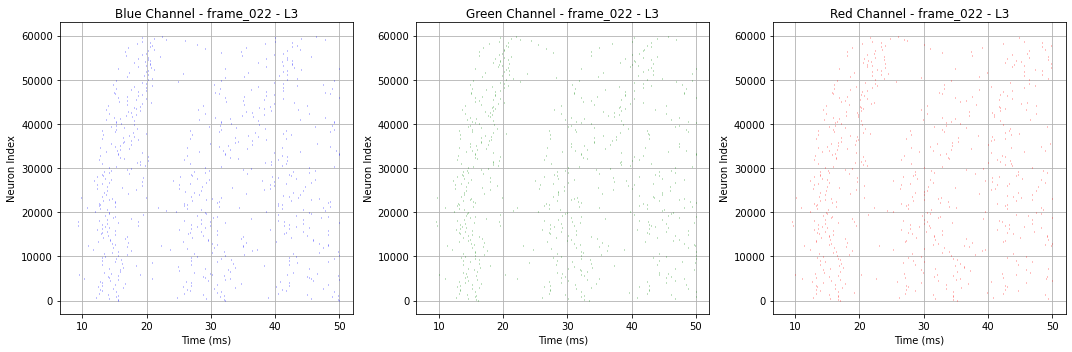

Setting currents for Red channel: 100%|█| 60000/60000 [00:58<00:00, 1029.38it/s]


Reading image frame_023...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:43<00:00, 1366.62it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:43<00:00, 1365.33it/
Setting currents for Red channel: 100%|▉| 59877/60000 [00:42<00:00, 1430.69it/s]

Simulating for frame_023
Simulation completed for frame_023
Subtracting the propagation delay: 13.0 ms.


Setting currents for Red channel: 100%|█| 60000/60000 [00:53<00:00, 1430.69it/s]

Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


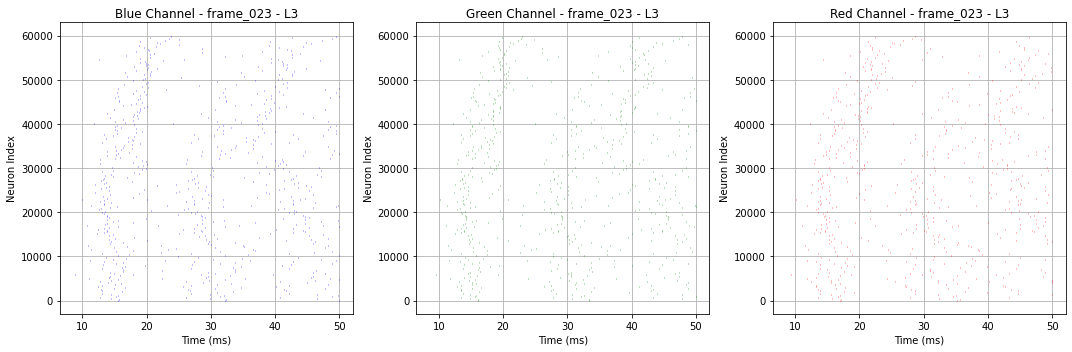

Setting currents for Red channel: 100%|█| 60000/60000 [00:59<00:00, 1009.99it/s]


Reading image frame_024...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:44<00:00, 1354.12it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:44<00:00, 1352.11it/
Setting currents for Red channel: 100%|▉| 59957/60000 [00:42<00:00, 1423.75it/s]

Simulating for frame_024
Simulation completed for frame_024
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


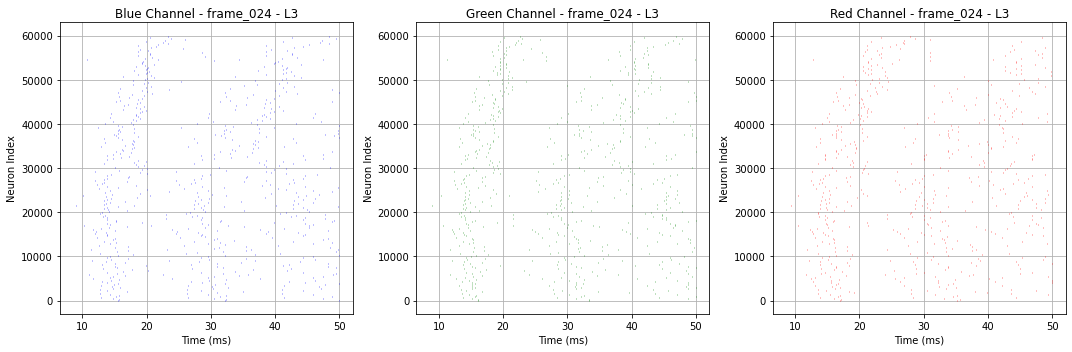

Setting currents for Red channel: 100%|██| 60000/60000 [01:00<00:00, 995.91it/s]


Reading image frame_025...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:43<00:00, 1368.55it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:43<00:00, 1368.93it/
Setting currents for Red channel: 100%|▉| 59995/60000 [00:42<00:00, 1387.31it/s]

Simulating for frame_025
Simulation completed for frame_025
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


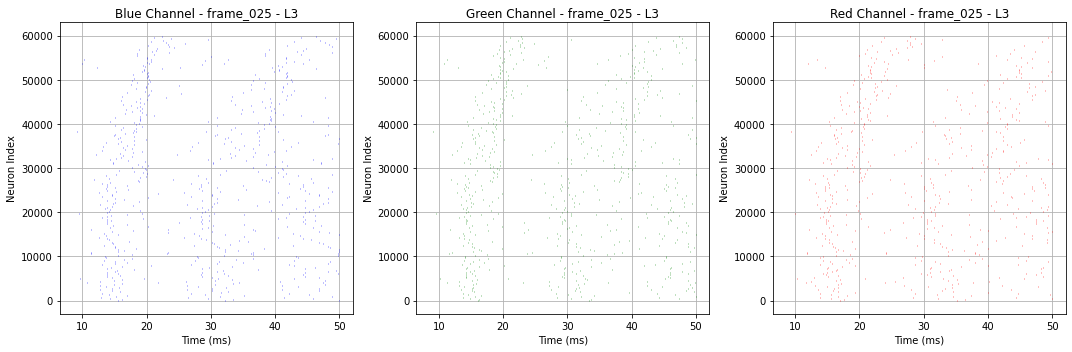

Setting currents for Red channel: 100%|█| 60000/60000 [00:59<00:00, 1003.86it/s]


Reading image frame_026...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:43<00:00, 1366.52it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:43<00:00, 1368.22it/
Setting currents for Red channel: 100%|▉| 59963/60000 [00:42<00:00, 1422.01it/s]

Simulating for frame_026
Simulation completed for frame_026
Subtracting the propagation delay: 13.0 ms.


Setting currents for Red channel: 100%|█| 60000/60000 [00:52<00:00, 1422.01it/s]

Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


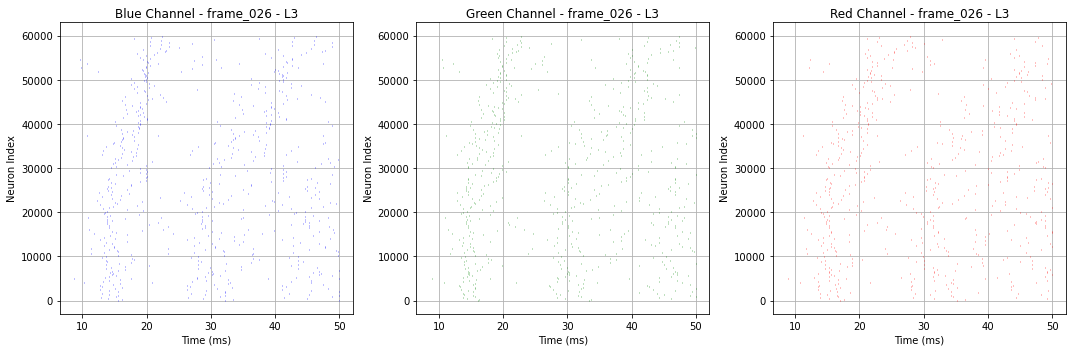

Setting currents for Red channel: 100%|██| 60000/60000 [01:00<00:00, 999.17it/s]


Reading image frame_027...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:44<00:00, 1353.80it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:44<00:00, 1357.59it/
Setting currents for Red channel: 100%|▉| 59910/60000 [00:42<00:00, 1408.98it/s]

Simulating for frame_027
Simulation completed for frame_027
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


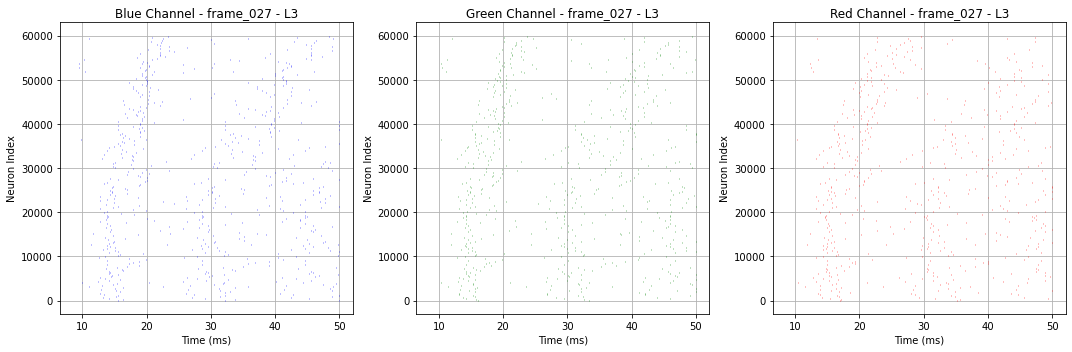

Setting currents for Red channel: 100%|██| 60000/60000 [01:00<00:00, 989.14it/s]


Reading image frame_028...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:44<00:00, 1342.23it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:44<00:00, 1363.01it/
Setting currents for Red channel: 100%|▉| 59946/60000 [00:42<00:00, 1416.99it/s]

Simulating for frame_028
Simulation completed for frame_028
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


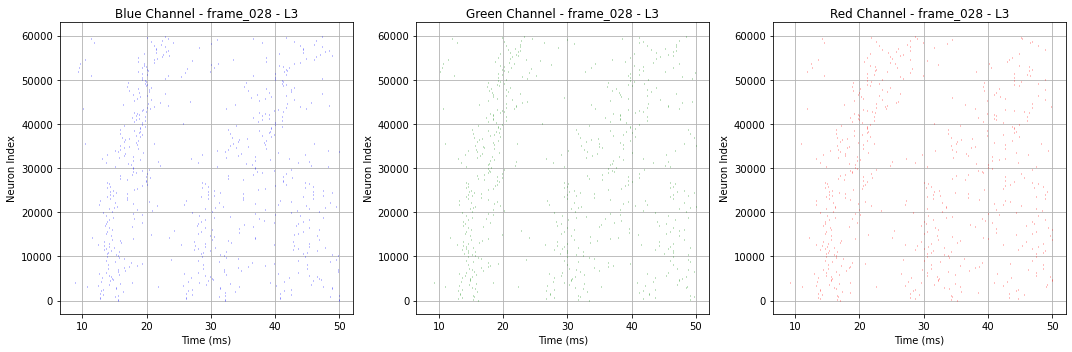

Setting currents for Red channel: 100%|██| 60000/60000 [01:01<00:00, 982.67it/s]


Reading image frame_029...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:44<00:00, 1342.09it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:44<00:00, 1357.67it/
Setting currents for Red channel: 100%|▉| 59926/60000 [00:43<00:00, 1389.09it/s]

Simulating for frame_029
Simulation completed for frame_029
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


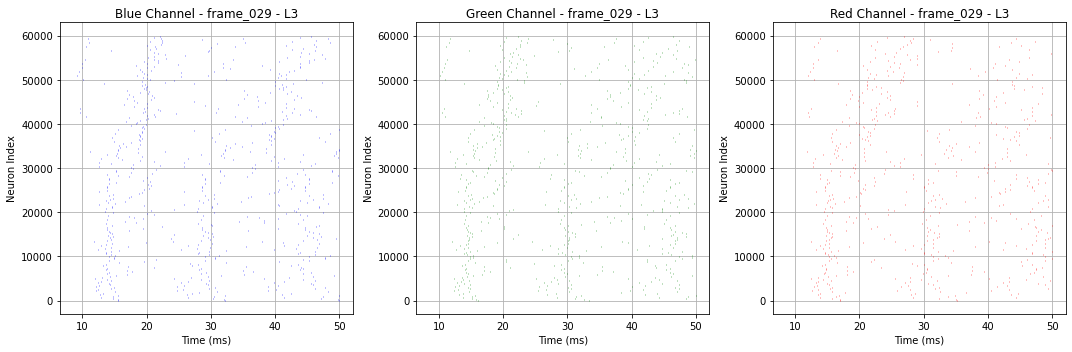

Setting currents for Red channel: 100%|██| 60000/60000 [01:01<00:00, 972.21it/s]


Reading image frame_030...
Image dimensions: Height: 200, Width: 300


Setting currents for Blue channel: 100%|█| 60000/60000 [00:44<00:00, 1344.65it/s
Setting currents for Green channel: 100%|█| 60000/60000 [00:44<00:00, 1363.24it/
Setting currents for Red channel: 100%|█| 60000/60000 [00:52<00:00, 1426.29it/s]

Simulating for frame_030
Simulation completed for frame_030
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.
Subtracting the propagation delay: 13.0 ms.


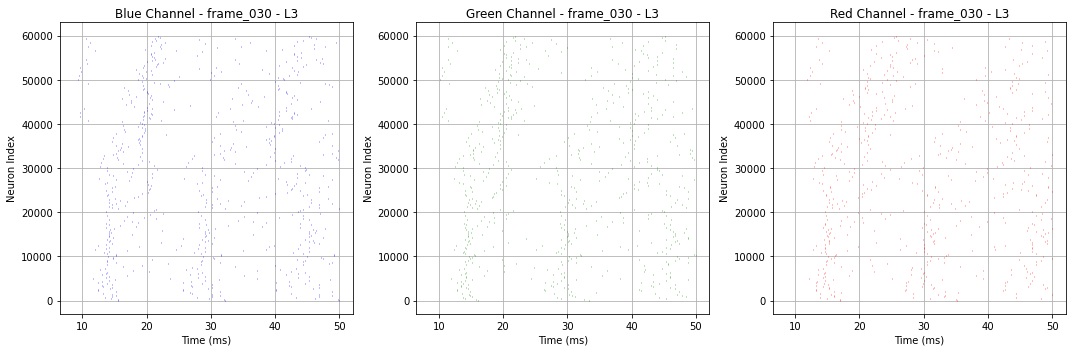

Setting currents for Red channel: 100%|██| 60000/60000 [01:01<00:00, 977.84it/s]


In [4]:
import cv2
import matplotlib.pyplot as plt
import nest
import numpy as np
import os
import h5py
from tqdm import tqdm

results_dir = "image_encoding_results/"
raster_plots_dir = "raster_plots_img/"
rows = 200 #240
cols = 300 #340

def pixel_intensity_to_current(intensity, offset=380):
    return intensity + offset

def resize_image(image, target_size=(cols, rows)):
    if target_size is None:
        return image
    else:
        return cv2.resize(image, target_size)

def simulate_raster_plot(image_file, current_funcs, sim_time=50.0, pd=13.0):
    os.system('clear')
    sim_time1 = sim_time + pd
    image_folder_path = os.path.join(raster_plots_dir, image_file)
    os.makedirs(image_folder_path, exist_ok=True)

    print("Reading image {}...".format(image_file))
    image = cv2.imread(os.path.join(images_folder, image_file + image_extension))
    resized_image = resize_image(image)
    height, width, _ = resized_image.shape
    print("Image dimensions: Height: {}, Width: {}".format(height, width))

    nest.ResetKernel()
    nest.set_verbosity(20)
    nest.SetKernelStatus({'print_time': False})

    layers_L1 = []
    layers_L2 = []
    layers_L3 = []
    spikerecorders_L1 = []
    spikerecorders_L2 = []
    spikerecorders_L3 = []

    for i, color in enumerate(['Blue', 'Green', 'Red']):
        layers_L1.append(nest.Create('iaf_psc_alpha', width * height))
        layers_L2.append(nest.Create('iaf_psc_alpha', width * height))
        layers_L3.append(nest.Create('iaf_psc_alpha', width * height))
        spikerecorders_L1.append(nest.Create("spike_recorder"))
        spikerecorders_L2.append(nest.Create("spike_recorder"))
        spikerecorders_L3.append(nest.Create("spike_recorder"))

        progress_bar = tqdm(total=height * width, desc="Setting currents for {} channel".format(color), position=0,
                            leave=True)

        for row in range(height):
            for col in range(width):
                intensity = resized_image[row, col, i]
                current = current_funcs[i](intensity)

                neuron_index = row * width + col
                nest.SetStatus(layers_L1[i][neuron_index], {"I_e": current})
                nest.Connect(layers_L1[i][neuron_index], layers_L2[i][neuron_index], "one_to_one",
                             syn_spec={"weight": 1200.0})
                nest.Connect(layers_L2[i][neuron_index], layers_L3[i][neuron_index], "one_to_one",
                             syn_spec={"weight": 1200.0})
                progress_bar.update(1)

        nest.Connect(layers_L1[i], spikerecorders_L1[i])
        nest.Connect(layers_L2[i], spikerecorders_L2[i])
        nest.Connect(layers_L3[i], spikerecorders_L3[i])

    print("Simulating for", image_file)
    nest.Simulate(sim_time1)
    print("Simulation completed for", image_file)

    os.makedirs(results_dir, exist_ok=True)
    with h5py.File(os.path.join(results_dir, image_file + "_spikes.h5"), "w") as file:
        for i, color in enumerate(['Blue', 'Green', 'Red']):
            events = spikerecorders_L3[i].get("events")
            senders = events["senders"]
            times = events["times"]
            grp = file.create_group(color)
            grp.create_dataset("senders", data=senders)
            grp.create_dataset("times", data=times)
            grp.attrs["image_filename"] = image_file
            grp.attrs["image_dimensions"] = (height, width)
            grp.attrs["simulation_time"] = sim_time

        # Plot raster plot for each color channel
        plt.figure(figsize=(15, 5))
        for i, color in enumerate(['Blue', 'Green', 'Red']):
            plt.subplot(1, 3, i + 1)
            plt.title('{} Channel - {} - L3'.format(color, image_file))
            plt.xlabel('Time (ms)')
            plt.ylabel('Neuron Index')
            plt.grid()
            ts = spikerecorders_L3[i].get("events")["times"]
            if (np.min(ts) > pd):
                print("Subtracting the propagation delay:", pd, "ms.")
                ts = ts - pd

            senders = spikerecorders_L3[i].get("events")["senders"] - np.min(
            spikerecorders_L3[i].get("events")["senders"])  # normalise values between 0 and cols*rows-1
            # print(np.min(senders),np.max(senders),(cols*rows))
            np.save(os.path.join(results_dir, image_file + "_" + color + "_L3_senders.npy"), senders)
            np.save(os.path.join(results_dir, image_file + "_" + color + "_L3_ts.npy"), ts)
            plt.vlines(ts, senders, senders + 1, color=color.lower(), linewidths=0.5)
        plt.tight_layout()
        plt.show()

images_folder = 'frames/'
image_extension = '.png'
image_files = ['frame_021', 'frame_022', 'frame_023', 'frame_024', 'frame_025', 'frame_026', 'frame_027',
               'frame_028', 'frame_029', 'frame_030']

for image_file in image_files:
    simulate_raster_plot(image_file, [pixel_intensity_to_current] * 3)



# Sound mp3 to wav

Sound Information:
Number of samples: 1311744
Length (seconds): 29.744761904761905
Minimum value: -9458
Maximum value: 9406


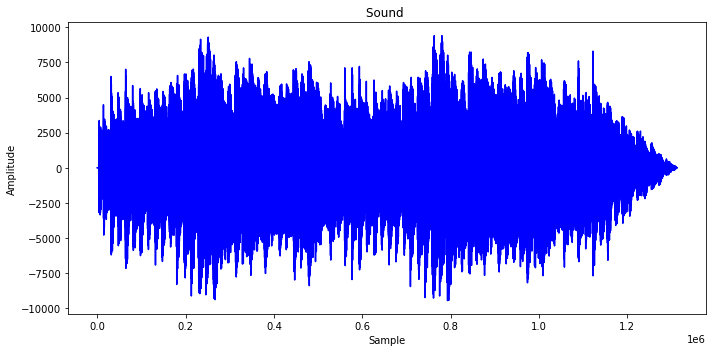

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from pydub import AudioSegment
import io
from scipy.io import wavfile

filename = 'sounds/audio.mp3'
# Function to convert mp3 to wav and return its data
def read_mp3(filename):
    sound = AudioSegment.from_mp3(filename)
    with io.BytesIO() as wav_data:
        sound.export(wav_data, format="wav")
        wav_data.seek(0)
        rate, data = wavfile.read(wav_data)
    return rate, data

# Function to display sound file information
def display_info(data, rate):
    num_samples = len(data)
    length = len(data) / rate
    min_val = np.min(data)
    max_val = np.max(data)
    print("Number of samples:", num_samples)
    print("Length (seconds):", length)
    print("Minimum value:", min_val)
    print("Maximum value:", max_val)

# Read the mp3 files
rateAudio, dataAudio = read_mp3(filename)

# Display information about each sound file
print("Sound Information:")
display_info(dataAudio, rateAudio)


# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(dataAudio, color='blue')  # Plot data1 in blue
plt.title('Sound ')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

plt.tight_layout()
plt.show()

# Store the data in npy files
np.save('sounds/dataAudio.npy', dataAudio)
np.save('sounds/rateAudio.npy', rateAudio)



# current spike values

For 379 the number of spikes is 1
For 414 the number of spikes is 2
For 480 the number of spikes is 3
For 504 the number of spikes is 4
For 505 the number of spikes is 5
For 506 the number of spikes is 6
For 507 the number of spikes is 7
For 508 the number of spikes is 8
For 509 the number of spikes is 11
Result: [[378, 0], [379, 1], [414, 2], [480, 3], [504, 4], [505, 5], [506, 6], [507, 7], [508, 8], [509, 11]]


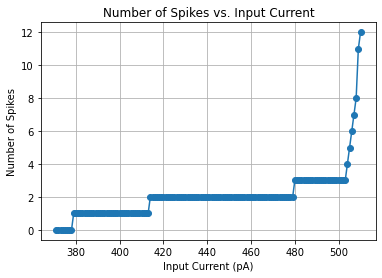

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import nest

# Reset the NEST kernel
nest.ResetKernel()
nest.set_verbosity(20)  # Set NEST verbosity level to 20

# Create a spike recorder
spike_recorder = nest.Create('spike_recorder')

# Initialize variables and lists
currents = []  # List to store input currents
spike_counts = []  # List to store spike counts
min_current = 0  # Variable to store the minimum current
inc = 1  # Increment value for increasing the current
current = 370  # Initial current value
num_spikes = 0  # Variable to store the number of spikes
neuron_params = {
    'C_m': 250.0,       # Membrane capacitance (pF)
    'tau_m': 10.0,      # Membrane time constant (ms)
    't_ref': 2.0,       # Refractory period (ms)
    'E_L': 0.0,         # Resting membrane potential (mV)
    'V_th': 20.0,       # Threshold potential (mV)
    'V_reset': 10.0,    # Reset potential (mV)
    'tau_syn_ex': 0.5,  # Excitatory synaptic time constant (ms)
    'tau_syn_in': 0.5   # Inhibitory synaptic time constant (ms)
}

# Create a single neuron with the IAF_PSC_ALPHA model
neuron = nest.Create('iaf_psc_alpha')

# List to store current and spike count pairs where number of spikes increased
current_spikes_values = [[0, 0]]
current_spikes_idx = 0  # Index for current_spikes_values list
actual_number_spikes = 0  # Actual number of spikes observed
number_spikes = 0  # Number of spikes observed

# Connect the neuron to the spike recorder
nest.Connect(neuron, spike_recorder)

# Loop through the input currents from 200 to 500 in increments of 10
while current < 800 and num_spikes < 12:
    nest.SetStatus(neuron, neuron_params)
    nest.SetStatus(spike_recorder, {'n_events': 0})
    neuron = nest.Create('iaf_psc_alpha')

    # Connect the neuron to the spike recorder
    nest.Connect(neuron, spike_recorder)

    # Set the input current to the neuron
    nest.SetStatus(neuron, {'I_e': current})
    current += inc  # Increment the current

    # Simulate for 50 ms
    nest.Simulate(50.0)

    # Get the number of spikes recorded by the spike recorder
    num_spikes = nest.GetStatus(spike_recorder, 'n_events')[0]

    # Store the current and spike count
    currents.append(current)
    spike_counts.append(num_spikes)

    # Record the current and spike count if the number of spikes increased
    if num_spikes == 0 and current > min_current:
        min_current = current
        current_spikes_values[0][0] = current
        number_spikes = 0
        current_spikes_idx = 1
    if num_spikes > 0:
        if num_spikes > actual_number_spikes:
            if len(current_spikes_values) < 10:
                current_spikes_values.append([current, num_spikes])
                actual_number_spikes = num_spikes
                print("For", current, "the number of spikes is", num_spikes)
            else:
                break

# Print the result
print("Result:", current_spikes_values)

# Save the current_spikes_values as npy file
np.save('sound_results/current_spikes_values.npy', current_spikes_values)

# Plot the number of spikes for different increments
plt.plot(currents, spike_counts, marker='o')
plt.title('Number of Spikes vs. Input Current')
plt.xlabel('Input Current (pA)')
plt.ylabel('Number of Spikes')
plt.grid(True)
plt.show()


# Sound Encoding 

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import nest
import time as tm  # Import time module with an alias
import h5py

# Function to chunk data into chunks of specified duration
def chunk_data(data, rate, duration_sec):
    chunk_size = int(rate * duration_sec)
    num_chunks = len(data) // chunk_size
    chunks = [data[i * chunk_size: (i + 1) * chunk_size] for i in range(num_chunks)]
    return chunks

# Function to plot data
def plot_data(data, title):
    plt.figure(figsize=(10, 5))
    plt.plot(data)
    plt.title(title)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')
    plt.show()

# Function to plot raster plot
def raster_plot(raster_data, chunk_idx, num_total_neurons):
    plt.figure(figsize=(10, 5))
    plt.eventplot(raster_data, colors='black')
    plt.title(f'Raster Plot for Chunk {chunk_idx + 1}')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.xlim(0, 50)  # Limit x-axis to 50 ms
    plt.ylim(0, num_total_neurons)
    plt.show()

def get_current_for_idx(idx):
    # Load the current_spikes_values from npy file
    current_spikes_values = np.load('sound_results/current_spikes_values.npy')

    # Check if the index is within the valid range
    if 0 <= idx < len(current_spikes_values):
        return current_spikes_values[idx][0]
    else:
        raise ValueError("Index out of range")

# Function to get currents for a given value
def get_currents_for_value(value):
    # Create an array to store currents for each neuron
    currents = np.zeros(6)

    # Normalize the value to be within the range of -99999 to 99999
    value = max(-99999, min(value, 99999))

    # Compute currents for each neuron
    if value >= 0:
        currents[5] = get_current_for_idx(0)  # Neuron 5: No spike for positive values
    else:
        currents[5] = get_current_for_idx(1)  # Neuron 5: Activate negative spike neuron
    currents[0] = get_current_for_idx(value % 10)  # Neuron 0: Increment of 1
    currents[1] = get_current_for_idx((value // 10) % 10)  # Neuron 1: Increment of 10
    currents[2] = get_current_for_idx((value // 100) % 10)  # Neuron 2: Increment of 100
    currents[3] = get_current_for_idx((value // 1000) % 10)  # Neuron 3: Increment of 1000
    currents[4] = get_current_for_idx((value // 10000) % 10)  # Neuron 4: Increment of 10000
    return currents

# Function to simulate SNN and plot results
def simulate_snn(chunks, num_total_neurons, data_num, num_chunks_to_simulate=10): # added num_chunks_to_simulate argument
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})
    neuron_model = 'iaf_psc_alpha'
    pop_left = nest.Create(neuron_model, num_total_neurons, params=neuron_params)
    pop_right= nest.Create(neuron_model, num_total_neurons, params=neuron_params)
    spike_detector_left = nest.Create('spike_recorder')
    spike_detector_right = nest.Create('spike_recorder')

    nest.Connect(pop_left, spike_detector_left)
    nest.Connect(pop_right, spike_detector_right)

    num_chunks = min(len(chunks), num_chunks_to_simulate) # Limit the number of chunks processed
    total_time = 0
    for chunk_idx, chunk in enumerate(chunks[:num_chunks]): # Process only the specified number of chunks
        print("Simulating chunk", (chunk_idx+1), "of", num_chunks, "...")
        start_time = tm.time()  # Use the imported time module alias
        neuron_idx = 0

        # Reset neuron parameters and spike recorder
        nest.SetStatus(pop_left, neuron_params)
        nest.SetStatus(pop_right, neuron_params)

        for sample in chunk:
            # Convert amplitude to current and scale to suitable range
            currents_left = get_currents_for_value(sample[0])
            currents_right = get_currents_for_value(sample[1])

            # Set the current to 6 neurons of the left channel
            for i in range(0,6):
                nest.SetStatus(pop_left[neuron_idx], {'I_e': currents_left[i]})
                nest.SetStatus(pop_right[neuron_idx], {'I_e': currents_right[i]})
                neuron_idx+=1

        nest.Simulate(50.0)  # Simulate for 50 ms

        end_time = tm.time()
        chunk_time = end_time - start_time
        total_time += chunk_time
        print(f"Chunk {chunk_idx+1} processing time: {chunk_time} seconds")

    # Get spike times
    events_left = spike_detector_left.get("events")
    senders_left = events_left["senders"]
    ts_left = events_left["times"]

    events_right = spike_detector_right.get("events")
    senders_right = events_right["senders"]
    ts_right = events_right["times"]

    np.save(f'sound_results/data{data_num}_left_senders.npy', senders_left)
    np.save(f'sound_results/data{data_num}_left_ts.npy', ts_left)
    np.save(f'sound_results/data{data_num}_right_senders.npy', senders_right)
    np.save(f'sound_results/data{data_num}_right_ts.npy', ts_right)
    # Save senders and timestamps in an HDF5 file
    filename = f"sound_results/data{data_num}_spike_results.h5"
    with h5py.File(filename, "w") as file:
        file.create_dataset("senders_left", data=senders_left)
        file.create_dataset("ts_left", data=ts_left)
        file.create_dataset("senders_right", data=senders_right)
        file.create_dataset("ts_right", data=ts_right)
    print(f"Total processing time for data{data_num}: {total_time} seconds")


neuron_params = {
    'C_m': 250.0,       # Membrane capacitance (pF)
    'tau_m': 10.0,      # Membrane time constant (ms)
    't_ref': 2.0,       # Refractory period (ms)
    'E_L': 0.0,         # Resting membrane potential (mV)
    'V_th': 20.0,       # Threshold potential (mV)
    'V_reset': 10.0,    # Reset potential (mV)
    'tau_syn_ex': 0.5,  # Excitatory synaptic time constant (ms)
    'tau_syn_in': 0.5   # Inhibitory synaptic time constant (ms)
}

# Load the data from npy files
data1 = np.load('sounds/dataAudio.npy')
rate1 = np.load('sounds/rateAudio.npy')

# Chunk the data into chunks of 1/30 second
chunk_duration = 1 / 30  # seconds
chunks1 = chunk_data(data1, rate1, chunk_duration)

num_samples1 = len(chunks1[0])
num_neurons_per_sample = 6 # 6 neurons per channel, 2 channels

for chunks, num_samples, data_num in zip([chunks1], [num_samples1], [1]):
    num_total_neurons = num_samples * num_neurons_per_sample
    # Simulate SNN for each chunk of data
    if chunks is chunks1:
        print("\nSimulating SNN for Sound 01 chunks:")
    else:
        print("\nSimulating SNN for Sound 02 chunks:")
    simulate_snn(chunks, num_total_neurons, data_num, num_chunks_to_simulate=10) # specify num_chunks_to_simulate



Simulating SNN for Sound 01 chunks:
Simulating chunk 1 of 10 ...
Chunk 1 processing time: 7.364416122436523 seconds
Simulating chunk 2 of 10 ...
Chunk 2 processing time: 7.463315963745117 seconds
Simulating chunk 3 of 10 ...
Chunk 3 processing time: 7.467759847640991 seconds
Simulating chunk 4 of 10 ...
Chunk 4 processing time: 7.451084136962891 seconds
Simulating chunk 5 of 10 ...
Chunk 5 processing time: 7.3793065547943115 seconds
Simulating chunk 6 of 10 ...
Chunk 6 processing time: 7.401147365570068 seconds
Simulating chunk 7 of 10 ...
Chunk 7 processing time: 7.396012783050537 seconds
Simulating chunk 8 of 10 ...
Chunk 8 processing time: 7.38653826713562 seconds
Simulating chunk 9 of 10 ...
Chunk 9 processing time: 7.401581287384033 seconds
Simulating chunk 10 of 10 ...
Chunk 10 processing time: 7.380029678344727 seconds
Total processing time for data1: 74.09119200706482 seconds


#### layer 2: How many populations of neurons? How many neurons per populations? Which neuron models were used? What are the connectivity types? Provide a table with all the parameterisations for the neurons and synapses

Use  one of the following neuron models:

    iaf_psc_exp – Leaky integrate-and-fire neuron model with exponential PSCs
    iaf_psc_alpha – Leaky integrate-and-fire model with alpha-shaped input currents
    izhikevich – Izhikevich neuron model
    mat2_psc_exp – Non-resetting leaky integrate-and-fire neuron model with exponential PSCs and adaptive threshold
    parrot_neuron_ps – Neuron that repeats incoming spikes - precise spike timing version


##### Neurons
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


##### Synapses
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Connectivity details
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Does the architecture changes during the training and inference phases? If you answer yes, explain why.

**Propagation Delay**

Propagation delay between L1 and L2: 7.0 ms.
Propagation delay between L2 and L3: 6.0 ms.
Propagation delay between L1 and L3: 13.0 ms.


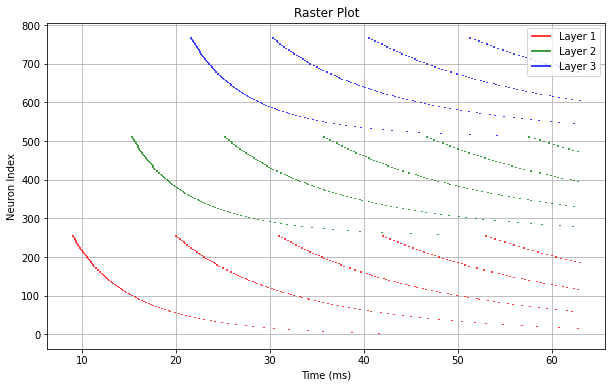

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import nest

# Reset NEST kernel
nest.ResetKernel()

# Set simulation parameters
propagation_delay=13.0 #See below how to get the propagation delay
sim_time = 50.0+propagation_delay# in milliseconds
offset = 380  # Offset value for analog input
# Define the analog values from 0 to 255
min_analog_value = 0 + offset
max_analog_value = 255 + offset
num_neurons = 256

# Create neuron populations
L1_neurons = nest.Create("iaf_psc_alpha", num_neurons)
L2_neurons = nest.Create("iaf_psc_alpha", num_neurons)
L3_neurons = nest.Create("iaf_psc_alpha", num_neurons)

ind=0
for value in range(min_analog_value, max_analog_value):
    # Set current for each neuron
    nest.SetStatus(L1_neurons[ind], {"I_e": value})
    ind+=1

# Connect neurons with one-to-one connections
for idx in range(num_neurons):
    nest.Connect(L1_neurons[idx], L2_neurons[idx], "one_to_one", syn_spec={"weight": 1200.0})  # 800.0 is a high synaptic weight to perform by-pass
    nest.Connect(L2_neurons[idx], L3_neurons[idx], "one_to_one", syn_spec={"weight": 1200.0})

# Create spike recorder
spikerecorder_L1 = nest.Create("spike_recorder")
spikerecorder_L2 = nest.Create("spike_recorder")
spikerecorder_L3 = nest.Create("spike_recorder")

# Connect spike recorder to neurons
nest.Connect(L1_neurons, spikerecorder_L1)
nest.Connect(L2_neurons, spikerecorder_L2)
nest.Connect(L3_neurons, spikerecorder_L3)


# Simulate network
nest.Simulate(sim_time)


# Get spike events from spike recorders
spike_events_L1 = nest.GetStatus(spikerecorder_L1, "events")[0]
spike_events_L2 = nest.GetStatus(spikerecorder_L2, "events")[0]
spike_events_L3 = nest.GetStatus(spikerecorder_L3, "events")[0]
senders_L1 = spike_events_L1["senders"]
ts_L1 = spike_events_L1["times"]
senders_L2 = spike_events_L2["senders"]
ts_L2 = spike_events_L2["times"]
senders_L3 = spike_events_L3["senders"]
ts_L3 = spike_events_L3["times"]

print("Propagation delay between L1 and L2:",(ts_L2[0]-ts_L1[0]),"ms.")
print("Propagation delay between L2 and L3:",(ts_L3[0]-ts_L2[0]),"ms.")
print("Propagation delay between L1 and L3:",(ts_L3[0]-ts_L1[0]),"ms.")

# Output
# Propagation delay between L1 and L2: 7.0 ms.
# Propagation delay between L2 and L3: 6.0 ms.
# Propagation delay between L1 and L3: 13.0 ms.


# Plot raster plot with different colors per layer
plt.figure(figsize=(10, 6))

# Plot spikes for Layer 1
senders_L1 = spike_events_L1["senders"]
ts_L1 = spike_events_L1["times"]
plt.vlines(ts_L1, senders_L1, senders_L1 + 1, color='red', label='Layer 1')

# Plot spikes for Layer 2
senders_L2 = spike_events_L2["senders"]
ts_L2 = spike_events_L2["times"]
plt.vlines(ts_L2, senders_L2, senders_L2 + 1, color='green', label='Layer 2')

# Plot spikes for Layer 3
senders_L3 = spike_events_L3["senders"]
ts_L3 = spike_events_L3["times"]
plt.vlines(ts_L3, senders_L3, senders_L3 + 1, color='blue', label='Layer 3')

plt.xlabel('Time (ms)')
plt.ylabel('Neuron Index')
plt.title('Raster Plot')
plt.legend()
plt.grid()
plt.show()



# Image Normalisation 3D

Processing frame_021 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


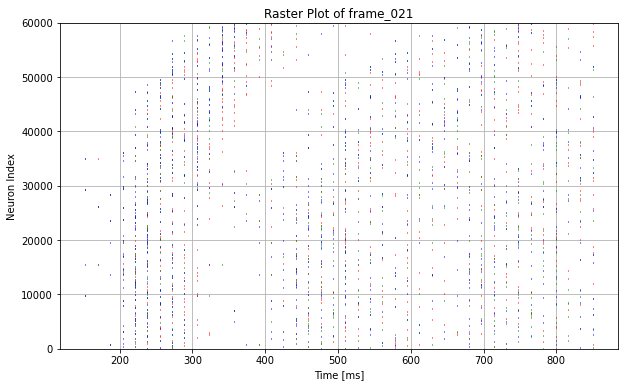

Processing frame_022 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


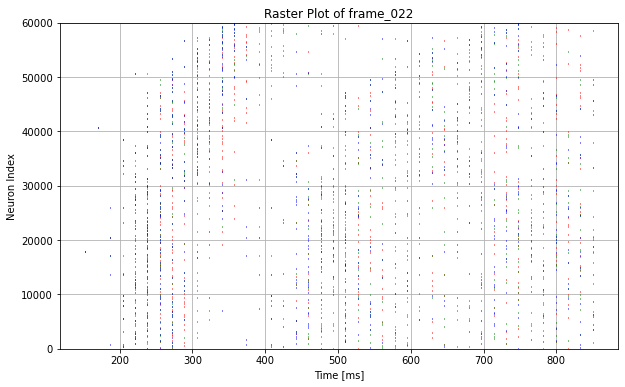

Processing frame_023 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


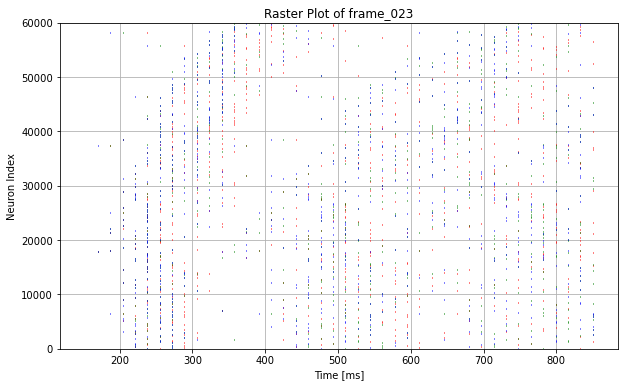

Processing frame_024 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


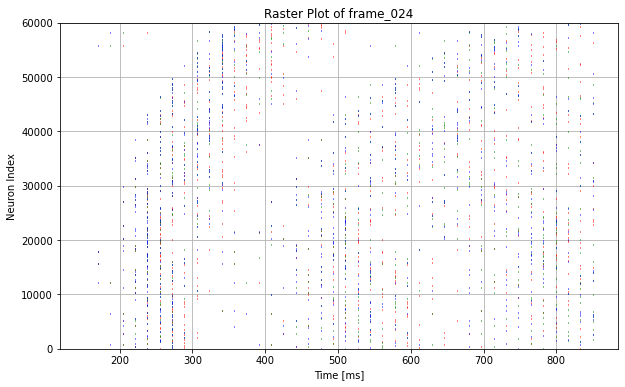

Processing frame_025 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


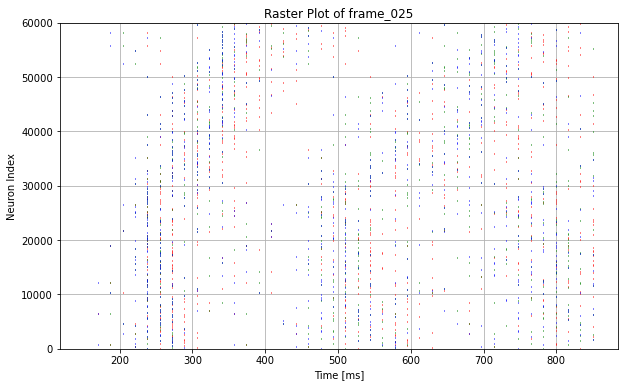

Processing frame_026 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


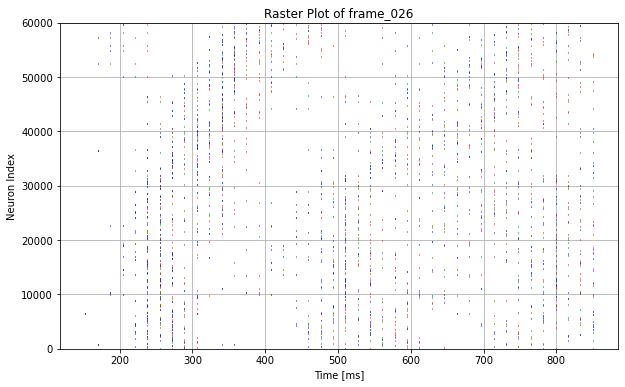

Processing frame_027 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


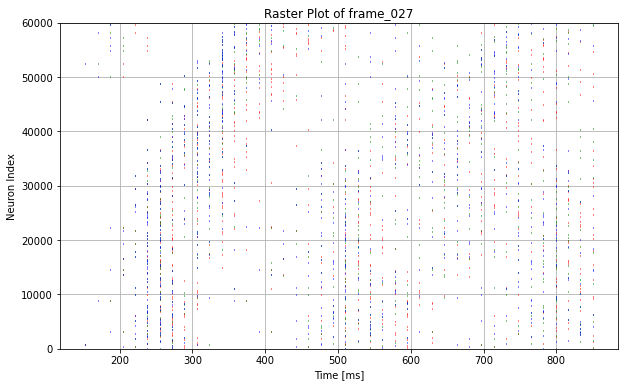

Processing frame_028 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


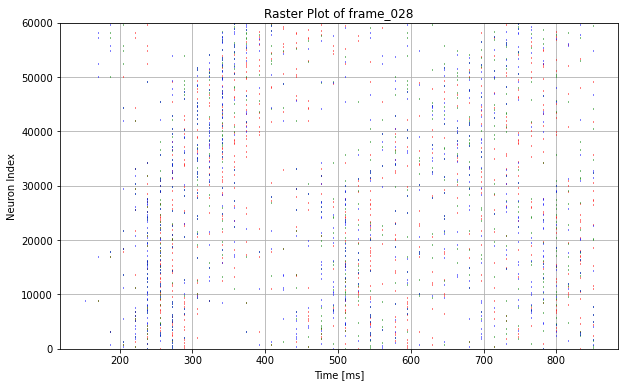

Processing frame_029 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


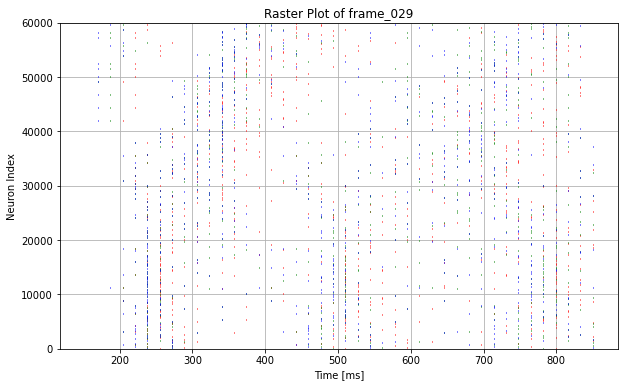

Processing frame_030 ...
normalised_3Dmat: 8.75 MB

Preparing plot for red ...
Preparing plot for green ...
Preparing plot for blue ...
Done!


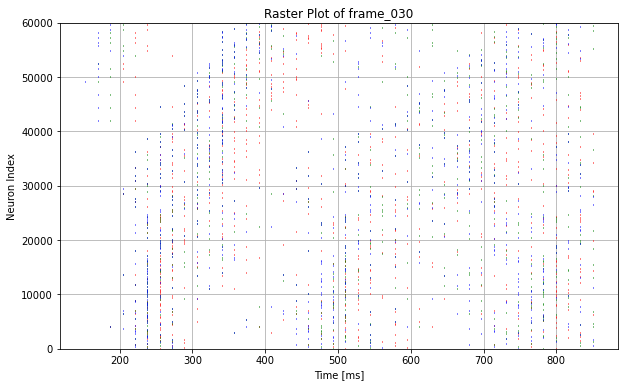

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def create_normalised_3D_matrix(fig,times_red, senders_red, times_green, senders_green, times_blue, senders_blue, cols):
    rows=200*300
    normalised_3Dmat = np.zeros((rows, cols,3))
    for i in range(len(times_red)):
        normalised_3Dmat[int(senders_red[i]-1), int(np.round(times_red[i], 0)),0] = 1.0 # red
    for i in range(len(times_green)):
        normalised_3Dmat[int(senders_green[i]-1), int(np.round(times_green[i], 0)), 1] = 1.0 # green
    for i in range(len(times_blue)):
        normalised_3Dmat[int(senders_blue[i]-1), int(np.round(times_blue[i], 0)), 2] = 1.0  # blue
    normalised_3Dmat.dump(f"normalised_mat_results/normalised_3Dmat_{fig}.npy")
    return normalised_3Dmat.astype(bool)

def plot_results(fig, normalised_3Dmat, cols):
    """
    Plot the raster plot.

    Parameters:
        fig (str): Figure name.
        normalised_3Dmat (numpy.ndarray): Normalised 3D matrix of spike events.
        cols (int): Number of time bins.
    """
    # Print size
    print(f"normalised_3Dmat: {np.round((normalised_3Dmat.nbytes) / (1024 * 1024), 2)} MB")
    print()

    # Plot the raster plot
    plt.figure(figsize=(10, 6))
    for channel, color in enumerate(['red', 'green', 'blue']):
        print(f"Preparing plot for {color} ...")
        for idx in range(normalised_3Dmat.shape[0]):
            spike_times = np.where(normalised_3Dmat[idx, :, channel])[0] * (cols // 3)  # Adjust the indexing
            if len(spike_times) > 0:
                plt.vlines(spike_times, idx, idx + 1, color=color, linewidth=1)
    print("Done!")
    plt.xlabel('Time [ms]')
    plt.ylabel('Neuron Index')
    plt.title(f"Raster Plot of {fig}")
    plt.ylim(0, normalised_3Dmat.shape[0])
    plt.grid(True)
    plt.savefig(f"nomalised3d_raster_plot/{fig}_raster_plot.png")
    plt.show()



# List of figure names
figures = ['frame_021', 'frame_022', 'frame_023', 'frame_024', 'frame_025', 'frame_026', 'frame_027',
               'frame_028', 'frame_029', 'frame_030']

# List colour names
colours = ["Red","Green","Blue"]
cols=51 # time in ms

# Loop over each figure
for idx in range(0,len(figures)):
    # Read events and senders from files
    print(f"Processing {figures[idx]} ...")
    times_red = np.load(f"image_encoding_results/{figures[idx]}_Red_L3_ts.npy", allow_pickle=True)
    senders_red = np.load(f"image_encoding_results/{figures[idx]}_Red_L3_senders.npy", allow_pickle=True)
    times_green = np.load(f"image_encoding_results/{figures[idx]}_Green_L3_ts.npy", allow_pickle=True)
    senders_green = np.load(f"image_encoding_results/{figures[idx]}_Green_L3_senders.npy", allow_pickle=True)
    times_blue = np.load(f"image_encoding_results/{figures[idx]}_Blue_L3_ts.npy", allow_pickle=True)
    senders_blue = np.load(f"image_encoding_results/{figures[idx]}_Blue_L3_senders.npy", allow_pickle=True)

    # Create the normalized 2D matrix
    normalised_3Dmat = create_normalised_3D_matrix(figures[idx],times_red, senders_red, times_green, senders_green, times_blue, senders_blue, cols)

    # Print image_encoding_results and plot raster plot
    plot_results(figures[idx], normalised_3Dmat,cols)


# Image Normalisation 2D

In [11]:
import numpy as np
import nest


def pixel_intensity_to_current(intensity, offset=380):
    return intensity + offset

def create_normalised_2D_matrix(times, senders, cols):
    rows=np.max(senders)+1
    normalised_2Dmat = np.zeros((rows, cols))
    for i in range(len(times)):
        normalised_2Dmat[int(senders[i]), int(np.round(times[i], 0))] = 1.0
    normalised_2Dmat.dump(f"normalised_mat_results/normalised_2Dmat.npy")
    return normalised_2Dmat.astype(bool)

def find_spike_pattern(pattern, nor12malised_2Dmat):
    """
    Find the index of the spike pattern in the normalized 2D matrix.

    Parameters:
        pattern (numpy.ndarray): Spike pattern to search for.
        normalised_2Dmat (numpy.ndarray): Normalized 2D matrix of spike events.

    Returns:
        int: Index of the spike pattern if found, -1 otherwise.
    """
    for idx in range(normalised_2Dmat.shape[0]):
        if np.array_equal(normalised_2Dmat[idx], pattern):
            return idx
    return -1


# Function to generate random spike patterns
def generate_random_pattern(length):
    random_array = np.random.randint(2, size=length)
    return random_array


# Reset NEST kernel
nest.ResetKernel()

# Define the number of neurons
num_neurons = 256
offset = 380

# Create layer with iaf_psc_alpha neurons
layer = nest.Create('iaf_psc_alpha', num_neurons)

spikerecorder = nest.Create("spike_recorder")

# Define the analog values from 0 to 255
min_analog_value = 0+offset
max_analog_value = 255+offset

# Create spike generators for each neuron and inject analog values
ind=0
for value in range(min_analog_value, max_analog_value):
    # Set current for each neuron
    nest.SetStatus(layer[ind], {"I_e": value})
    ind+=1
nest.Connect(layer, spikerecorder)
# Simulate
nest.Simulate(50.0)

# Get spike times
events = spikerecorder.get("events")
senders = events["senders"]
ts = events["times"]

normalised_2Dmat=create_normalised_2D_matrix(ts,senders,51)


# Function to generate random spike patterns
def generate_random_pattern(length):
    return np.random.randint(2, size=length)



#test a known patterns
for i in range(50):
# Find the index of the pattern in the normalized 2D matrix
    idx = np.random.randint(256)
    pattern_index = find_spike_pattern(normalised_2Dmat[idx,:], normalised_2Dmat)
    # Print the result
    if pattern_index != -1:
        print(f"The analogue value for pattern {normalised_2Dmat[idx,:]} is {pattern_index}.")
    else:
        print(f"Pattern {i + 1}: Not found")

    # Generate a random spike pattern
    pattern_to_find = generate_random_pattern(51).astype(bool)


    # Find the index of the pattern in the normalized 2D matrix
    pattern_index = find_spike_pattern(pattern_to_find, normalised_2Dmat)
    # Print the result
    if pattern_index != -1:
        print(f"The analogue value for pattern {pattern_to_find} is {pattern_index}.")
    else:
        print(f"Pattern {i + 1}b: Not found")




The analogue value for pattern [False False False False False False False False False False  True False
 False False False False False False False False False False False  True
 False False False False False False False False False False False False
  True False False False False False False False False False False False
  True False False] is 198.
Pattern 1b: Not found
The analogue value for pattern [False False False False False False False False False False False False
 False False  True False False False False False False False False False
 False False False False False False False  True False False False False
 False False False False False False False False False False False  True
 False False False] is 113.
Pattern 2b: Not found
The analogue value for pattern [False False False False False False False False False False  True False
 False False False False False False False False False False False  True
 False False False False False False False False False False False False
  Tr

# Sound Normalisation 3D

0 8818
1 8819
++++++++++++++++++ Processing data1... +++++++++++++++++++++++
Starting normalisation ...
Processing left...
Left completed ...
Processing right...
Normalisation completed!
Preparing left raster plot...
Preparing right raster plot...


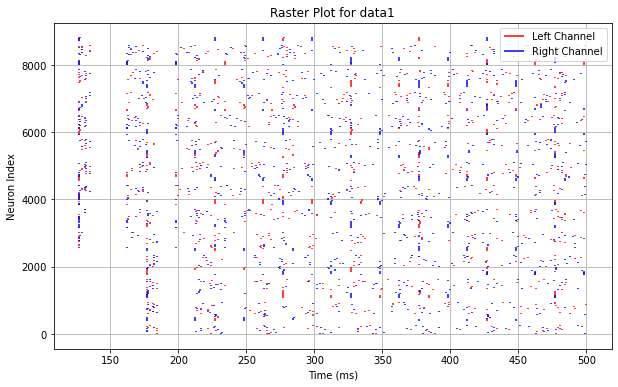

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Function to chunk data into chunks of specified duration
def chunk_data_info(data, rate, duration_sec):
    chunk_size = int(rate * duration_sec)
    num_chunks = len(data) // chunk_size
    return num_chunks, chunk_size
def create_normalised_3D_matrix(data_name, times_left, senders_left, times_right, senders_right, rows, cols):
    normalised_3Dmat = np.zeros((rows, cols, 2))
    print("Starting normalisation ...\nProcessing left...")
    for i in range(len(times_left)):
        normalised_3Dmat[int(senders_left[i]), int(np.round(times_left[i], 0)), 0] = 1.0  # left
    print("Left completed ...\nProcessing right...")
    for i in range(len(times_right)):
        normalised_3Dmat[int(senders_right[i] - 1), int(np.round(times_right[i], 0)), 1] = 1.0  # right
    np.save(f"sound_normalise_3d/normalised_3Dmat_{data_name}.npy", normalised_3Dmat, allow_pickle=True)
    print("Normalisation completed!")
    return normalised_3Dmat.astype(bool)



def raster_plot(normalised_3D_matrix, data):
    """
    Plot raster plot for spike events split between left and right channels.

    Parameters:
        normalised_3D_matrix (numpy.ndarray): 3D matrix split between left and right channels.
        data_num (int): Identifier for the data set.

    Returns:
        None
    """
    print("Preparing left raster plot...")
    num_neurons = normalised_3D_matrix.shape[0]

    # Plot raster plot for left channel
    plt.figure(figsize=(10, 6))
    for neuron_idx in range(num_neurons):
        left_spikes = np.where(normalised_3D_matrix[neuron_idx, :,0])[0]
        plt.vlines(left_spikes, neuron_idx, neuron_idx + 1, color='red', label='Left Channel' if neuron_idx == 0 else None)
    print("Preparing right raster plot...")
    # Plot raster plot for right channel
    for neuron_idx in range(num_neurons):
        right_spikes = np.where(normalised_3D_matrix[neuron_idx, :,1])[0]
        plt.vlines(right_spikes, neuron_idx, neuron_idx + 1, color='blue', label='Right Channel' if neuron_idx == 0 else None)
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron Index')
    plt.title(f'Raster Plot for {data}')
    plt.legend()
    plt.grid()
    plt.savefig(f"sound_raster_plot/{data}_raster_plot.png")
    plt.show()

# Load the data from npy files
data1 = np.load('sounds/dataAudio.npy')
rate1 = np.load('sounds/rateAudio.npy')
senders_left=[]
ts_left=[]
senders_right=[]
ts_right=[]
for data_num in ["1"]:
    senders_left.append(np.load(f'sound_results/data{data_num}_left_senders.npy'))
    ts_left.append(np.load(f'sound_results/data{data_num}_left_ts.npy'))
    senders_right.append(np.load(f'sound_results/data{data_num}_right_senders.npy'))
    ts_right.append(np.load(f'sound_results/data{data_num}_right_ts.npy'))

data_shape=[data1.shape]

reconstructed_data1=np.zeros(data_shape[0])

num_neurons_per_sample = 6
samp_period=1/30
time_step=60

data1_num_chunks, data1_chunk_size=chunk_data_info(data1,rate1,samp_period)
num_total_neurons = [data1_chunk_size * num_neurons_per_sample]
senders_left[0]=senders_left[0]-1 # normalisation
senders_right[0]=senders_right[0]-num_total_neurons[0] # normalisation
print(np.min(senders_left[0]),np.max(senders_left[0]))
print(np.min(senders_right[0]),np.max(senders_right[0]))


datas=["data1"]

# print(data1_num_total_neurons)
for i in range(len(datas)):
    print(f"++++++++++++++++++ Processing {datas[i]}... +++++++++++++++++++++++")
    num_cols = int(np.max([np.max(ts_left[i]), np.max(ts_right[i])])) + 1
    normalised_3Dmat=create_normalised_3D_matrix(datas[i],ts_left[i],senders_left[i],ts_right[i],senders_right[i],num_total_neurons[i],num_cols)
    raster_plot(normalised_3Dmat, datas[i])


#### noisy layer : How many populations of neurons? How many neurons per populations? Which neuron models were used? What are the connectivity types? Provide a table with all the parameterisations for the neurons and synapses

A noisy layer must be implemented after the encoding phase, subjecting the encoded information to at least one type of noise. Use oe of the noise types listed below. Justify your choice and its impact on the SNN.

    spike_generator – Generate spikes from an array with spike-times
    spike_train_injector – Neuron that emits prescribed spike trains.
    noise_generator – Generate a Gaussian white noise current
    poisson_generator – Generate spikes with Poisson process statistics
    poisson_generator_ps – Simulated neuron firing with Poisson process statistics - precise spike timing version with arbitrary dead times
    pulsepacket_generator – Generate sequence of Gaussian pulse packets
    sinusoidal_gamma_generator – Generates sinusoidally modulated gamma spike trains
    sinusoidal_poisson_generator – Generate sinusoidally modulated Poisson spike trains


##### Neurons
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


##### Synapses
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Connectivity details
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Does the architecture changes during the training and inference phases? If you answer yes, explain why.

#### lateral inhibition layer : How many populations of neurons? How many neurons per populations? Which neuron models were used? What are the connectivity types? Provide a table with all the parameterisations for the neurons and synapses
Use  one of the following neuron models:

    iaf_psc_exp – Leaky integrate-and-fire neuron model with exponential PSCs
    iaf_psc_alpha – Leaky integrate-and-fire model with alpha-shaped input currents
    izhikevich – Izhikevich neuron model
    mat2_psc_exp – Non-resetting leaky integrate-and-fire neuron model with exponential PSCs and adaptive threshold
    parrot_neuron_ps – Neuron that repeats incoming spikes - precise spike timing version
    
Lateral Inhibition and Synaptic Time Delays: Implement lateral inhibition within the SNN architecture to enhance competition among neighboring neurons, refining the encoding and decoding processes. Incorporate synapses with different time delays in the network, allowing for varied temporal interactions between neurons. Discuss the rationale behind the choice of time delays and their impact on information processing within the spiking neural network.


##### Neurons
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


##### Synapses
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Connectivity details
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Does the architecture changes during the training and inference phases? If you answer yes, explain why.

#### layer 3 (decoding layer): How many populations of neurons? How many neurons per populations? Which neuron models were used? What are the connectivity types? Provide a table with all the parameterisations for the neurons and synapses


1. Engineer a decoding layer as the third segment, strategically designed to efficiently recover both audio and image from the encoded information.
2. Employ a sophisticated approach by incorporating inhibitory and excitatory synapses in the training process. Leverage either unsupervised or supervised learning to train the decoding layer, optimising the interplay between these synapses for enhanced performance.
Use  one of the following neuron models:

    iaf_psc_exp – Leaky integrate-and-fire neuron model with exponential PSCs
    iaf_psc_alpha – Leaky integrate-and-fire model with alpha-shaped input currents
    izhikevich – Izhikevich neuron model
    mat2_psc_exp – Non-resetting leaky integrate-and-fire neuron model with exponential PSCs and adaptive threshold
    parrot_neuron_ps – Neuron that repeats incoming spikes - precise spike timing version

Synaptic Learning in Decoding Layer:  Inhibitory and excitatory synapses must be incorporated in the training process of the decoding layer, leveraging either unsupervised or supervised learning. The interplay between these synapses should be optimised for enhanced performance.

Types of Synapses:

    stdp_synapse – Synapse type for spike-timing dependent plasticity
    static_synapse – Synapse type for static connections


##### Neurons
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


##### Synapses
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Connectivity details
| parameter | Description | value or range | IS units | 
| --------- | ----------- |--------------- | -------- |
| row 1     |             |                |          |


###### Does the architecture changes during the training and inference phases? If you answer yes, explain why.

# Image Decoding 

Processing frame_021 ...
(60000, 51, 3)


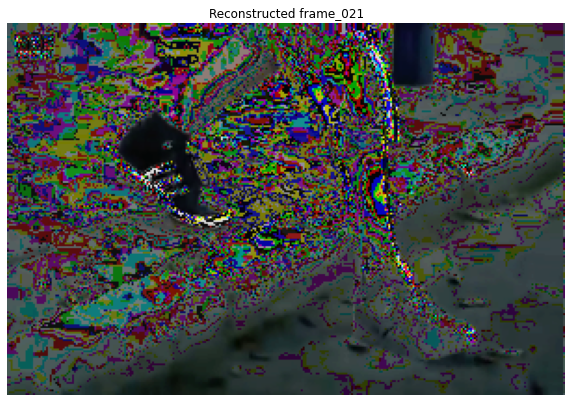

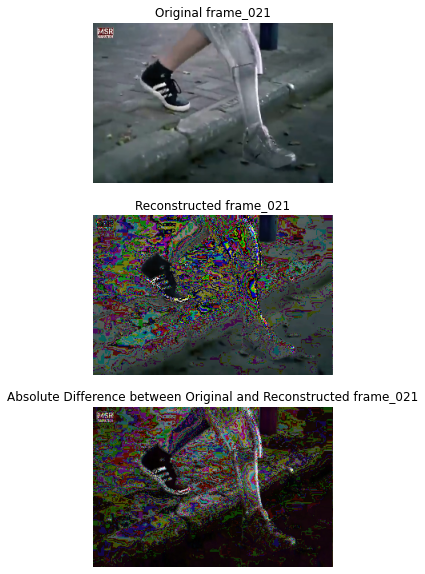

Processing frame_022 ...
(60000, 51, 3)


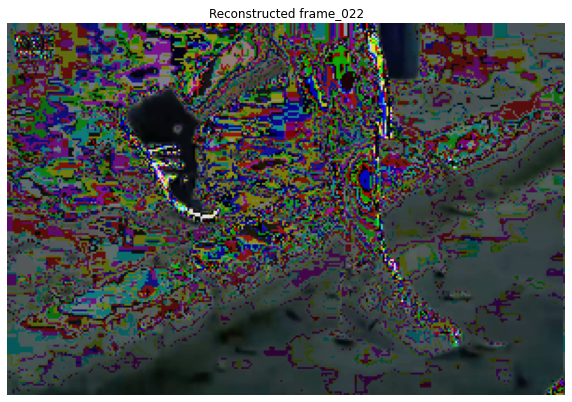

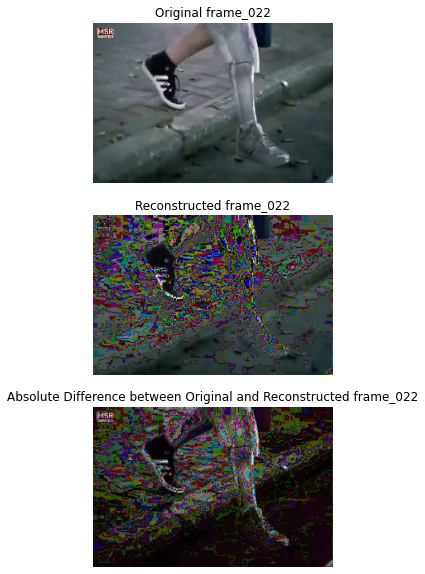

Processing frame_023 ...
(60000, 51, 3)


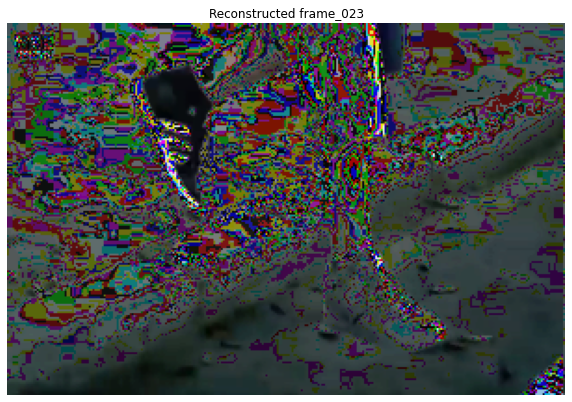

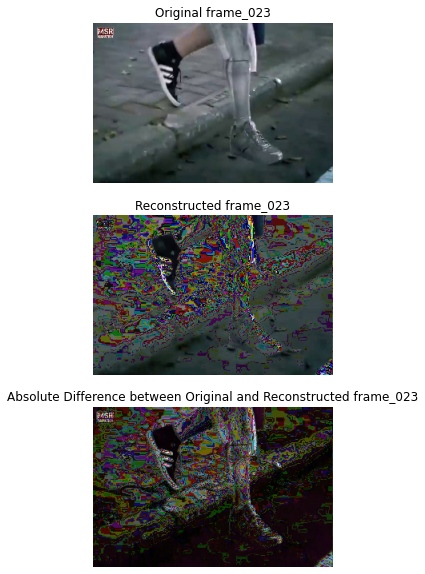

Processing frame_024 ...
(60000, 51, 3)


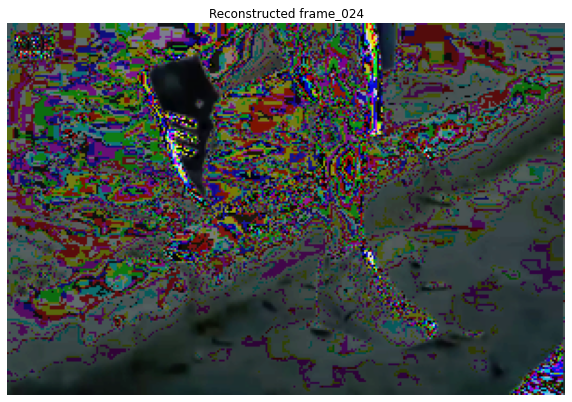

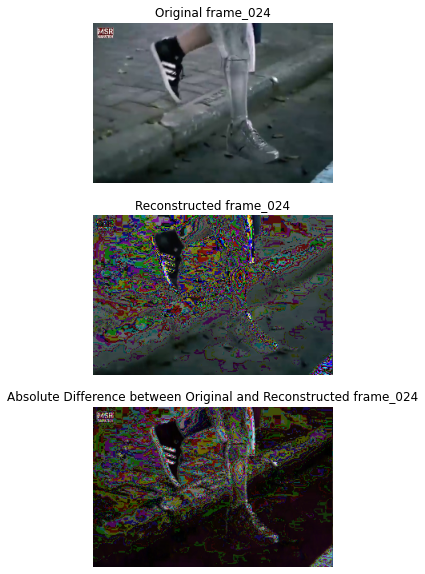

Processing frame_025 ...
(60000, 51, 3)


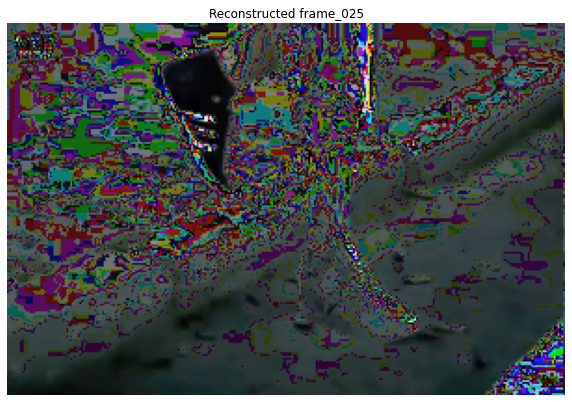

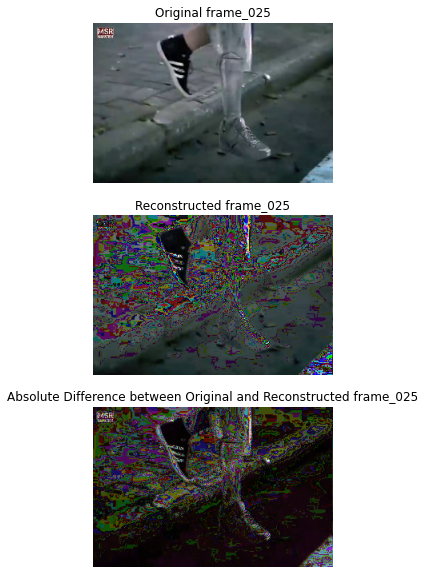

Processing frame_026 ...
(60000, 51, 3)


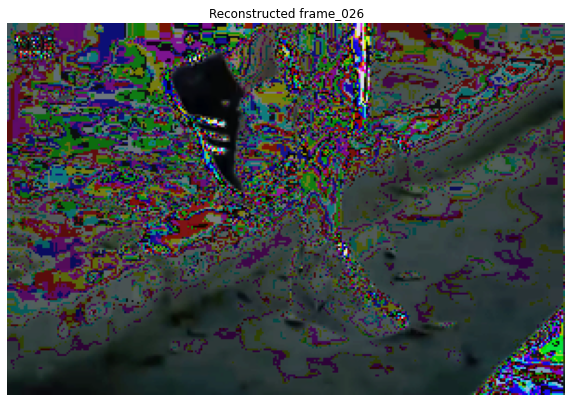

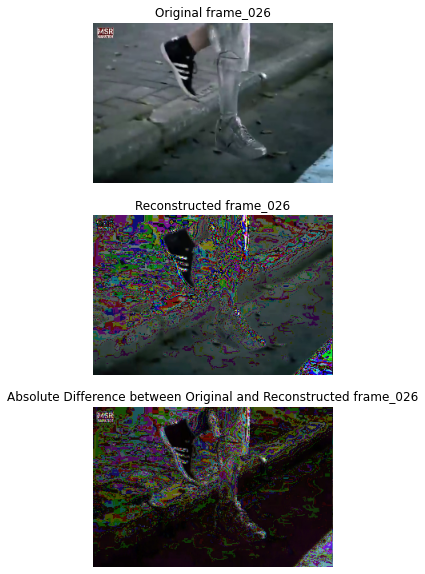

Processing frame_027 ...
(60000, 51, 3)


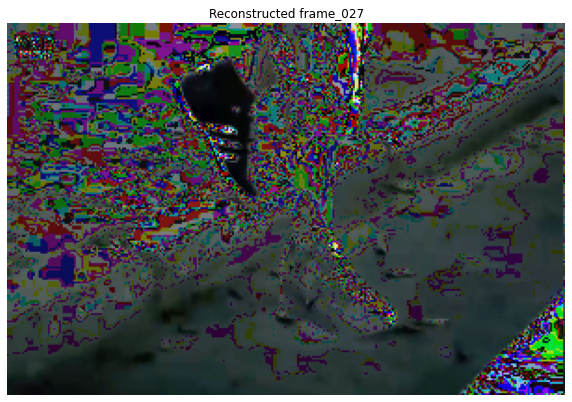

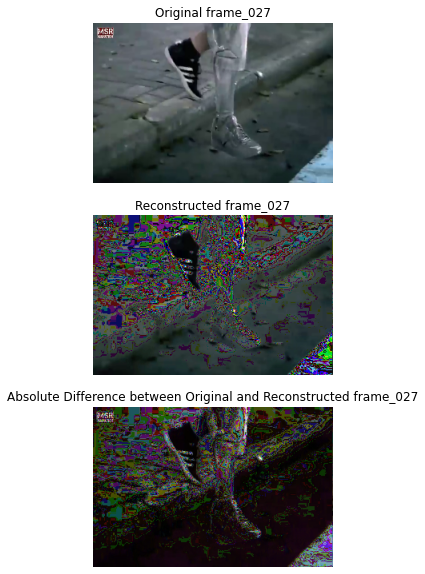

Processing frame_028 ...
(60000, 51, 3)


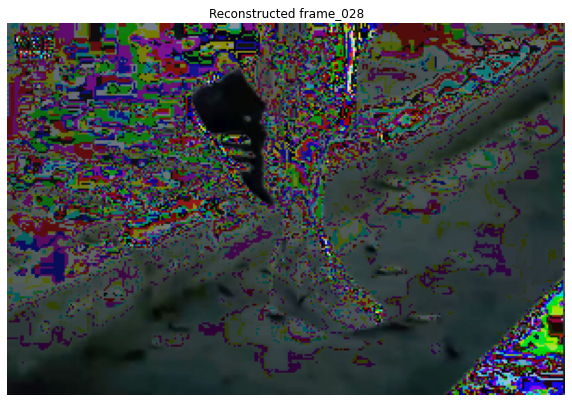

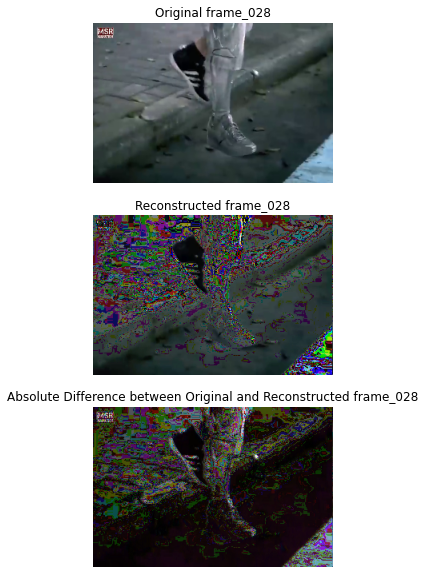

Processing frame_029 ...
(60000, 51, 3)


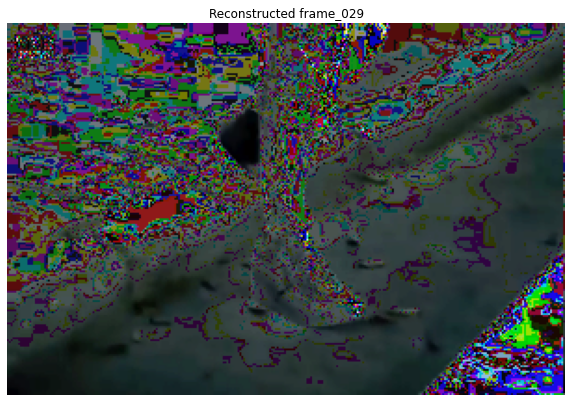

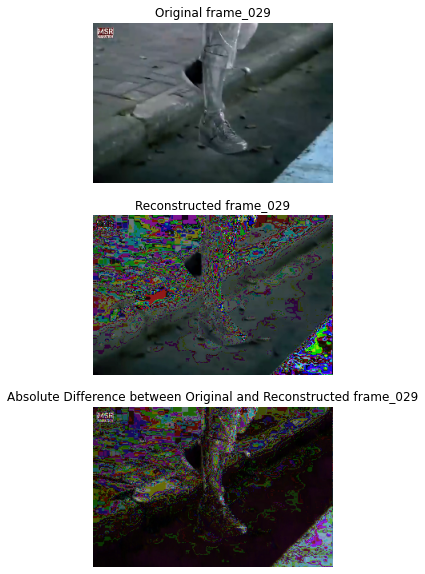

Processing frame_030 ...
(60000, 51, 3)


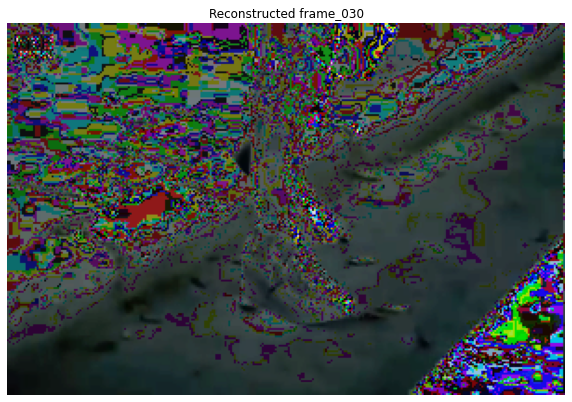

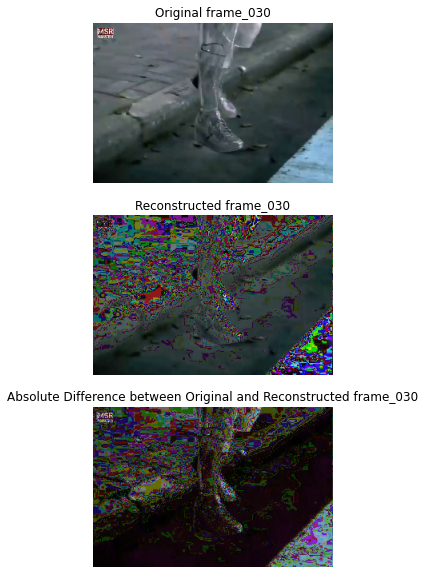

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def spikes_to_analog(pattern, normalised_2Dmat):
    min_distance = np.inf
    best_match_idx = -1
    for idx in range(normalised_2Dmat.shape[0]):
        distance = np.linalg.norm(pattern - normalised_2Dmat[idx])
        if distance < min_distance:
            min_distance = distance
            best_match_idx = idx
    return best_match_idx

# Load the normalised 2D matrix
normalised_2Dmat = np.load(f"normalised_mat_results/normalised_2Dmat.npy", allow_pickle=True)

# List of figure names
figures = ['frame_021', 'frame_022', 'frame_023', 'frame_024', 'frame_025', 'frame_026', 'frame_027',
               'frame_028', 'frame_029', 'frame_030']
for idx in range(len(figures)):
    # Read events and senders from files
    print(f"Processing {figures[idx]} ...")
    normalised_3Dmat = np.load(f"normalised_mat_results/normalised_3Dmat_{figures[idx]}.npy", allow_pickle=True)
    print(normalised_3Dmat.shape)

    # Create 2D matrix for each channel
    analogue_values_ch = np.zeros((200, 300, 3), dtype=np.uint8)
    for k in range(normalised_3Dmat.shape[2]):  # Iterate over the third dimension
        for i in range(normalised_3Dmat.shape[0]):
            tmp = spikes_to_analog(normalised_3Dmat[i, :, k], normalised_2Dmat)
            if tmp < 0:
                raise ValueError("Invalid value!")
            r, c = divmod(i, 300)  # Calculate row and column indices
            analogue_values_ch[r, c, k] = np.uint8(tmp)
    analogue_values_ch = np.array(analogue_values_ch)

    # Load original image
    original_image = cv2.imread(f"frames/{figures[idx]}.png")
    original_image_resized = cv2.resize(original_image, (300, 200))

    # Calculate the absolute difference between original and reconstructed images
    diff_image = cv2.absdiff(original_image_resized, analogue_values_ch)

    # Save and display the plot
    plt.figure(figsize=(10, 10))
    plt.imshow(analogue_values_ch)
    plt.title(f"Reconstructed {figures[idx]}")
    plt.axis('off')
    plt.savefig(f"reconstructedFigures/{figures[idx]}_reconstructed.png")
    plt.show()

    # Save and display the plot
    plt.figure(figsize=(10, 10))
    # Plot the original image
    plt.subplot(3, 1, 1)
    plt.imshow(cv2.cvtColor(original_image_resized, cv2.COLOR_BGR2RGB))
    plt.title(f"Original {figures[idx]}")
    plt.axis('off')

    # Plot the reconstructed image
    plt.subplot(3, 1, 2)
    plt.imshow(analogue_values_ch)
    plt.title(f"Reconstructed {figures[idx]}")
    plt.axis('off')

    # Plot the absolute difference image
    plt.subplot(3, 1, 3)
    plt.imshow(cv2.cvtColor(diff_image, cv2.COLOR_BGR2RGB))
    plt.title(f"Absolute Difference between Original and Reconstructed {figures[idx]}")
    plt.axis('off')

    # Save and display the plot
    plt.savefig(f"reconstructedFigures/{figures[idx]}_comparinson.png")
    plt.show()


# Sound Decoding 

Processing simualtion time-steps: 100%|███████████| 9/9 [00:19<00:00,  2.22s/it]


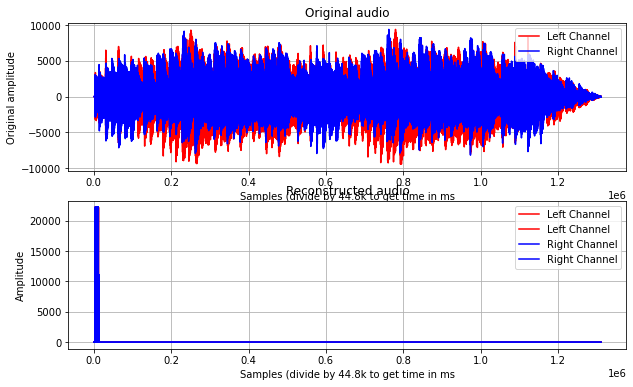

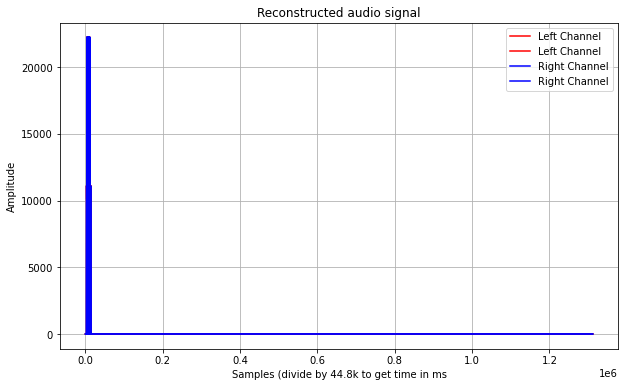

In [32]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

def get_idx_for_spike_count(spike_count):
    """
    This function takes a spike count and returns the index if it exists in the current_spikes_values numpy array.
    If the spike count does not exist in the array, it returns -1.

    Parameters:
        spike_count (int): The spike count to search for.

    Returns:
        int: The index if the spike count exists, otherwise -1.
    """
    # Load the current_spikes_values from npy file
    spike_values = np.load('sound_results/current_spikes_values.npy')[:, 1]

    # Iterate through the current_spikes_values array to find the index corresponding to the spike count
    for i in range(0,len(spike_values)):
        if spike_values[i] == spike_count:
            return i
    return -1

    # If the spike count does not exist in the array, return -1
    return -1

def reconstruct_value_from_values(values):
    """
    Reconstructs the value from the given vector of values.

    Parameters:
        currents (numpy.ndarray): Array containing currents for each neuron.

    Returns:
        int: Reconstructed value.
    """

    # Extract the indices of the spike counts corresponding to the given currents
    idx_neuron0 = get_idx_for_spike_count(values[0])
    idx_neuron1 = get_idx_for_spike_count(values[1])
    idx_neuron2 = get_idx_for_spike_count(values[2])
    idx_neuron3 = get_idx_for_spike_count(values[3])
    idx_neuron4 = get_idx_for_spike_count(values[4])
    idx_neuron5 = get_idx_for_spike_count(values[5])

    # Reconstruct the value based on the indices
    value = idx_neuron0 + \
            idx_neuron1 * 10 + \
            idx_neuron2 * 100 + \
            idx_neuron3 * 1000 + \
            idx_neuron4 * 10000

    # Check if the value should be negative
    if idx_neuron5 == 1:
        value *= -1
    return value


def calculate_spike_counts(neuron_matrix):
    """
    Calculate the spike counts for each neuron in a matrix.

    Parameters:
        neuron_matrix (numpy.ndarray): Matrix representing spike events of 6 neurons over 60 ms.

    Returns:
        numpy.ndarray: A vector containing the spike counts for each neuron.
    """
    # Sum along the columns to count spikes for each neuron
    spike_counts = np.sum(neuron_matrix, axis=1)
    return spike_counts

def reconstruct_value(normalised_3Dmat, x, y, data):
    """
    Reconstructs the value from a chunk of 6 neurons and 60 ms of simulation.

    Parameters:
        normalised_3Dmat (numpy.ndarray): 3D matrix containing spike events split between left and right channels.
        x (int): Number of chunks along the time axis.
        y (int): Number of chunks along the neuron axis.

    Returns:
        numpy.ndarray: Reconstructed values for each chunk.
    """
    simulation_ts = 60  # ms
    number_neurons_sample = 6
    reconstructed_vector = np.zeros((x, y, 2))

    # Extract the chunk of spike events for the given chunk index
    idx = 0
    for ts in tqdm(range(0, normalised_3Dmat.shape[1], simulation_ts), desc="Processing simualtion time-steps"):
        for neuron in range(0, normalised_3Dmat.shape[0], number_neurons_sample):
            chunk_left = normalised_3Dmat[neuron:neuron + number_neurons_sample, ts:ts + simulation_ts, 0]
            spike_counts_left = np.sum(chunk_left, axis=1)
            reconstructed_value_left = reconstruct_value_from_values(spike_counts_left)

            chunk_right = normalised_3Dmat[neuron:neuron + number_neurons_sample, ts:ts + simulation_ts, 1]
            spike_counts_right = np.sum(chunk_right, axis=1)
            reconstructed_value_right = reconstruct_value_from_values(spike_counts_right)

            reconstructed_vector[idx, 0] = reconstructed_value_left
            reconstructed_vector[idx, 1] = reconstructed_value_right
            idx += 1
    reconstructed_vector.dump(f"reconstructed_audio/reconstructed_{data}.npy")
    return reconstructed_vector

def plot_reconstructed_vector(reconstructed_data, original_data,data_name):
    """
    Plot the reconstructed vector.

    Parameters:
        reconstructed_vector (numpy.ndarray): Reconstructed values for each chunk.
        data_num (int): Identifier for the data set.

    Returns:
        None
    """
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.plot(original_data[:, 0], label='Left Channel', color='red')
    plt.plot(original_data[:, 1], label='Right Channel', color='blue')
    plt.xlabel('Samples (divide by 44.8k to get time in ms')
    plt.ylabel('Original amplitude')
    plt.title(f'Original {data_name}')
    plt.legend()
    plt.grid()

    plt.subplot(2,1,2)
    plt.plot(reconstructed_data[:, 0], label='Left Channel', color='red')
    plt.plot(reconstructed_data[:, 1], label='Right Channel', color='blue')
    plt.xlabel('Samples (divide by 44.8k to get time in ms')
    plt.ylabel('Amplitude')
    plt.title(f'Reconstructed {data_name}')
    plt.legend()
    plt.grid()
    plt.savefig(f"reconstructedSounds/{data_name}_results.png")
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(reconstructed_data[:, 0], label='Left Channel', color='red')
    plt.plot(reconstructed_data[:, 1], label='Right Channel', color='blue')
    plt.xlabel('Samples (divide by 44.8k to get time in ms')
    plt.ylabel('Amplitude')
    plt.title(f'Reconstructed {data_name} signal')
    plt.legend()
    plt.grid()
    plt.savefig(f"reconstructedSounds/reconstructed_{data_name}.png")
    plt.show()

data_names = ["audio"]
original_signals=[np.load('sounds/dataAudio.npy')]
original_rates=[np.load('sounds/rateAudio.npy')]
normalised_3Dmats=[np.load("sound_normalise_3d/normalised_3Dmat_data1.npy", allow_pickle=True)]


for i in range(len(data_names)):
    reconstructed_matrix=reconstruct_value(normalised_3Dmats[i],original_signals[i].shape[0],original_signals[i].shape[1],data_names[i])
    plot_reconstructed_vector(reconstructed_matrix, original_signals[i], data_names[i])

#### layer n [optional, add as many as you need]: How many populations of neurons? How many neurons per populations? Which neuron models were used? What are the connectivity types? Provide a table with all the parameterisations for the neurons and synapses

Use  one of the following neuron models:

    iaf_psc_exp – Leaky integrate-and-fire neuron model with exponential PSCs
    iaf_psc_alpha – Leaky integrate-and-fire model with alpha-shaped input currents
    izhikevich – Izhikevich neuron model
    mat2_psc_exp – Non-resetting leaky integrate-and-fire neuron model with exponential PSCs and adaptive threshold
    parrot_neuron_ps – Neuron that repeats incoming spikes - precise spike timing version


##### Neurons
| parameter    | Description | value or range | IS units | 
| -------- | ------- |------- | ------- |

###### Synapses
| parameter    | Description | value or range | IS units | 
| -------- | ------- |------- | ------- |

###### Connectivity details
| pre    | post | connectivity | Type (inhibitory or excitatory) | 
| -------- | ------- |------- | ------- |

###### Does the architecture changes during the training and inference phases? If you answer yes, explain why.

### Spike metrics
Spike Metrics Utilisation: Spike metrics must be employed to precisely quantify errors during the decoding process.

## SNN Training Paradigm:  
The SNN must be trained using the chosen learning paradigm (unsupervised or supervised) and use the encoded signal before exposure of noise as testing set.

    Unsupervised learning
    Supervised learning


**SNN without lateral inhibition**


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.6.0
 Built: Nov 16 2023 09:28:21

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

Step 1/20
Step 2/20
Step 3/20
Step 4/20
Step 5/20
Step 6/20
Step 7/20
Step 8/20
Step 9/20
Step 10/20
Step 11/20
Step 12/20
Step 13/20
Step 14/20
Step 15/20
Step 16/20
Step 17/20
Step 18/20
Step 19/20
Step 20/20


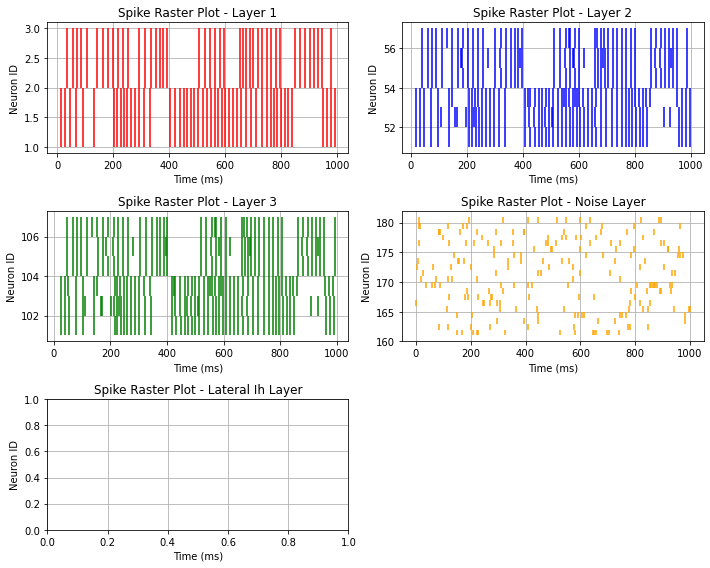

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nest


def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    plt.tight_layout()
    plt.savefig("snn_architecture_result/snn_raster_plot.png")
    plt.show()

def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 50)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 50)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 60)
    noise_layer = nest.Create("poisson_generator", 20)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 60)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)

    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_l2l3 = {"weight": 1200.0}
    syn_spec_lnl2 = {"weight": 1200.0}

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # Connect layer 2 to layer 3 individually
    for i in range(3):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Connect layer 2 to layer 3 individually
    for i in range(3, 6):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer)


simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0)

**SNN with lateral inhibition - static synapses**

Step 1/20
Step 2/20
Step 3/20
Step 4/20
Step 5/20
Step 6/20
Step 7/20
Step 8/20
Step 9/20
Step 10/20
Step 11/20
Step 12/20
Step 13/20
Step 14/20
Step 15/20
Step 16/20
Step 17/20
Step 18/20
Step 19/20
Step 20/20


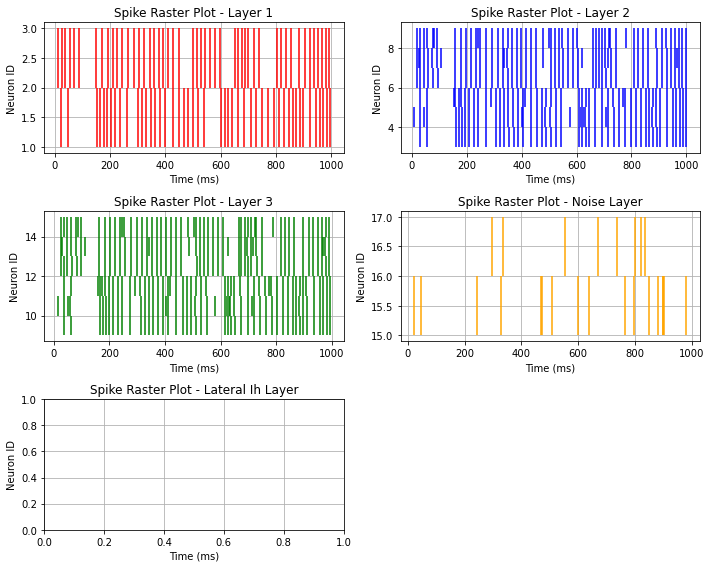

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import nest


def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    plt.tight_layout()
    plt.savefig("snn_architecture_result/static-synapses_raster_plot.png")
    plt.show()

def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 2)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 6)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 6)
    noise_layer = nest.Create("poisson_generator", 2)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 6)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)

    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_l1lih = {"weight":1200.0}
    syn_spec_l2l3 = {"weight": 1200.0}
    syn_spec_lnl2 = {"weight": 1200.0}
    syn_spec_l2ih = {"weight": 1200.0}
    syn_spec_ihl2 = {"weight": -420.0}

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1aih = [(neuron_layer1[0], lateral_ih_layer[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer1bih = [(neuron_layer1[1], lateral_ih_layer[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1aih:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer1bih:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of ih layer
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of ih layer
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of lateral ih layer
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1lih)

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of lateral ih 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1lih)

    # Connect layer 2 to layer 3 individually
    for i in range(3):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Connect layer 2 to layer 3 individually
    for i in range(3, 6):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)

    # compensation close loop approach with static synapses
    nest.Connect(lateral_ih_layer, neuron_layer2, syn_spec=syn_spec_l2ih)
    nest.Connect(neuron_layer2, lateral_ih_layer, syn_spec=syn_spec_ihl2)


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer)


simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0)

**SNN with lateral inhibition - STDP synapses**

Step 1/20
Step 2/20
Step 3/20
Step 4/20
Step 5/20
Step 6/20
Step 7/20
Step 8/20
Step 9/20
Step 10/20
Step 11/20
Step 12/20
Step 13/20
Step 14/20
Step 15/20
Step 16/20
Step 17/20
Step 18/20
Step 19/20
Step 20/20


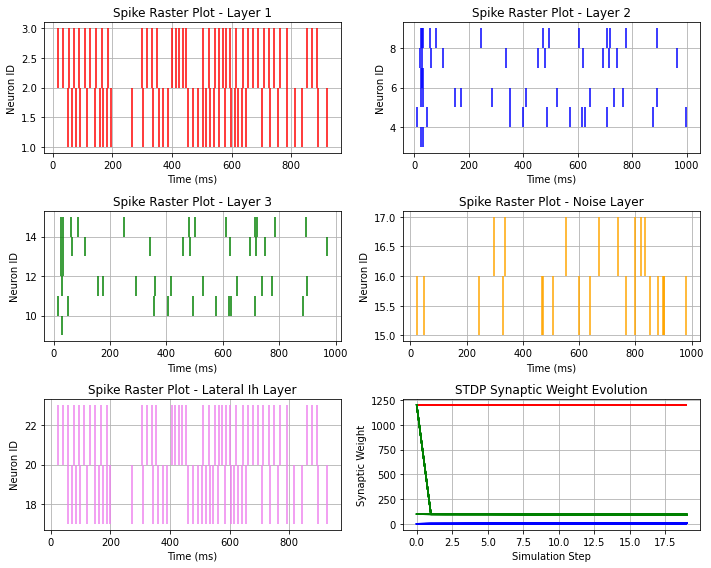

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import nest


def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer, weights):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    # STDP weights
    plt.subplot(3, 2, 6)
    plt.plot(weights[0], label='Layer 1 -> Ih Layer', color='red')
    plt.plot(weights[1], label='Layer 2 -> Ih Layer', color='blue')
    plt.plot(weights[2], label='Ih Layer -> Layer 2', color='green')
    plt.xlabel('Simulation Step')
    plt.ylabel('Synaptic Weight')
    plt.title('STDP Synaptic Weight Evolution')
    plt.grid()

    plt.tight_layout()
    plt.savefig("snn_architecture_result/STDP_synapses_raster_plot.png")
    plt.show()

def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 2)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 6)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 6)
    noise_layer = nest.Create("poisson_generator", 2)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 6)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)

    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_l1lih = {"synapse_model": "stdp_synapse","weight": 1200.0}
    syn_spec_l2l3 = {"weight": 1200.0}
    syn_spec_lnl2 = {"weight": 1200.0}
    syn_spec_l2ih = {"synapse_model": "stdp_synapse","weight": 1200.0}
    syn_spec_ihl2 = {"synapse_model": "stdp_synapse","weight": -600.0}

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1aih = [(neuron_layer1[0], lateral_ih_layer[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer1bih = [(neuron_layer1[1], lateral_ih_layer[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1aih:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer1bih:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of ih layer
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of ih layer
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of lateral ih layer
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1lih)

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of lateral ih 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1lih)

    # Connect layer 2 to layer 3 individually
    for i in range(3):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Connect layer 2 to layer 3 individually
    for i in range(3, 6):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)

    # compensation close loop approach with static synapses
    nest.Connect(lateral_ih_layer, neuron_layer2, syn_spec=syn_spec_l2ih)
    nest.Connect(neuron_layer2, lateral_ih_layer, syn_spec=syn_spec_ihl2)

    # Define synaptic weight recording for STDP connections
    stdp_synapse_weights_l1lih = []
    stdp_synapse_weights_l2ih = []
    stdp_synapse_weights_ihl2 = []


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)
        # Record synaptic weights after each simulation step
        stdp_synapse_weights_l1lih.append(nest.GetStatus(nest.GetConnections(neuron_layer1, lateral_ih_layer), "weight"))
        stdp_synapse_weights_l2ih.append(nest.GetStatus(nest.GetConnections(neuron_layer2, lateral_ih_layer), "weight"))
        stdp_synapse_weights_ihl2.append(nest.GetStatus(nest.GetConnections(lateral_ih_layer, neuron_layer2), "weight"))

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    weights=[stdp_synapse_weights_l1lih, stdp_synapse_weights_l2ih, stdp_synapse_weights_ihl2]
    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer, weights)


simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0)

**SNN without lateral inhibition - ReSuMe**

Step 1/20
Step 2/20
Step 3/20
Step 4/20
Step 5/20
Step 6/20
Step 7/20
Step 8/20
Step 9/20
Step 10/20
Step 11/20
Step 12/20
Step 13/20
Step 14/20
Step 15/20
Step 16/20
Step 17/20
Step 18/20
Step 19/20
Step 20/20


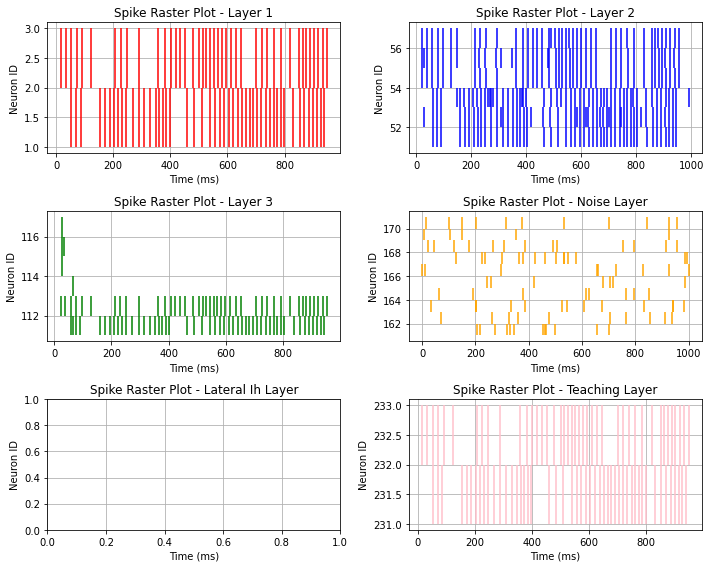

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import nest

def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,
                senders_teaching_layer,ts_teaching_layer):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    # Teaching Layer
    plt.subplot(3, 2, 6)
    plt.title('Spike Raster Plot - Teaching Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_teaching_layer, ts_teaching_layer):
        plt.vlines(spike_time, sender, sender + 1, color='pink')

    plt.tight_layout()
    plt.savefig("snn_architecture_result/snn_without_LH_ReSuMe._raster_plot.png")
    plt.show()

def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 50)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 60)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 50)
    noise_layer = nest.Create("poisson_generator", 10)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 60)
    teaching_layer = nest.Create("iaf_psc_alpha", 60)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")
    spike_recorder_teaching = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)
    nest.Connect(teaching_layer, spike_recorder_teaching)

    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_l2l3 = {"synapse_model": "stdp_synapse","weight": 1200.0}
    syn_spec_lnl2 = {"weight": 1200.0}
    syn_spec_tll3 = {"weight": 1200.0}

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # Connect layer 2 to layer 3 individually
    for i in range(3):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Connect layer 2 to layer 3 individually
    for i in range(3, 6):
        nest.Connect(neuron_layer2[i], neuron_layer3[i],  syn_spec=syn_spec_l2l3)

    # Connect teaching layer to layer 3 individually
    for i in range(3):
        nest.Connect(teaching_layer[i], neuron_layer3[i], syn_spec=syn_spec_tll3)

    # Connect teaching layer to layer 3 individually
    for i in range(3, 6):
        nest.Connect(teaching_layer[i], neuron_layer3[i], syn_spec=syn_spec_tll3)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})
            nest.SetStatus(teaching_layer[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]
    events_teaching_layer = nest.GetStatus(spike_recorder_teaching, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    senders_teaching_layer = events_teaching_layer["senders"]
    ts_teaching_layer = events_teaching_layer["times"]

    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,
                senders_teaching_layer,ts_teaching_layer)


simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0)

**SNN without lateral inhibition - ReSuMe**

Step 1/200
Step 2/200
Step 3/200
Step 4/200
Step 5/200
Step 6/200
Step 7/200
Step 8/200
Step 9/200
Step 10/200
Step 11/200
Step 12/200
Step 13/200
Step 14/200
Step 15/200
Step 16/200
Step 17/200
Step 18/200
Step 19/200
Step 20/200
Step 21/200
Step 22/200
Step 23/200
Step 24/200
Step 25/200
Step 26/200
Step 27/200
Step 28/200
Step 29/200
Step 30/200
Step 31/200
Step 32/200
Step 33/200
Step 34/200
Step 35/200
Step 36/200
Step 37/200
Step 38/200
Step 39/200
Step 40/200
Step 41/200
Step 42/200
Step 43/200
Step 44/200
Step 45/200
Step 46/200
Step 47/200
Step 48/200
Step 49/200
Step 50/200
Step 51/200
Step 52/200
Step 53/200
Step 54/200
Step 55/200
Step 56/200
Step 57/200
Step 58/200
Step 59/200
Step 60/200
Step 61/200
Step 62/200
Step 63/200
Step 64/200
Step 65/200
Step 66/200
Step 67/200
Step 68/200
Step 69/200
Step 70/200
Step 71/200
Step 72/200
Step 73/200
Step 74/200
Step 75/200
Step 76/200
Step 77/200
Step 78/200
Step 79/200
Step 80/200
Step 81/200
Step 82/200
Step 83/200
Step 84/200
S

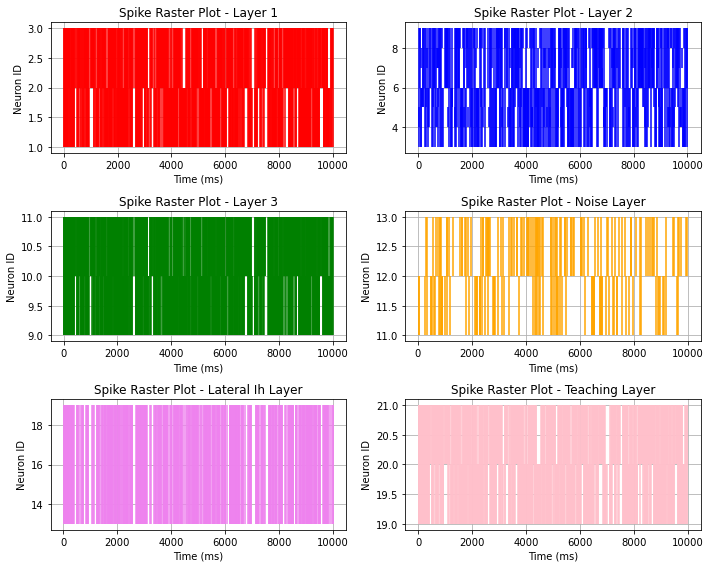

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os
import nest


def purpura_distance(spiketrain1, spiketrain2, cost):
    """
    spiketrain1 and spiketrain2 are vectors containing the spike times of two spike trains.
    cost is a parameter that determines the sensitivity of the distance calculation to the time differences between
    spikes.
    The function calculates the Victor-Purpura distance by iterating over the spike times of the two spike trains and
    summing exponential terms based on the time differences.
    The result is the Victor-Purpura distance, a measure of the dissimilarity between the spike trains.

    Parameters:
        spiketrain1 (array-like): Spike times of the first spike train.
        spiketrain2 (array-like): Spike times of the second spike train.
        cost (float): Cost parameter for the distance calculation.

    Returns:
        float: Victor-Purpura distance between the two spike trains.
    """
    # Ensure spiketrains are sorted
    spiketrain1 = np.sort(spiketrain1)
    spiketrain2 = np.sort(spiketrain2)

    # Initialize the Victor-Purpura distance
    distance = 0.0

    # Calculate the Victor-Purpura distance
    i = 0
    j = 0
    while i < len(spiketrain1) and j < len(spiketrain2):
        time_diff = spiketrain1[i] - spiketrain2[j]
        if time_diff > 0:
            distance += np.exp(-time_diff / cost)
            j += 1
        elif time_diff < 0:
            distance += np.exp(time_diff / cost)
            i += 1
        else:
            i += 1
            j += 1

    # Add remaining spikes from longer spike train
    while i < len(spiketrain1):
        distance += np.exp(-(spiketrain1[i] - spiketrain2[-1]) / cost)
        i += 1
    while j < len(spiketrain2):
        distance += np.exp(-(spiketrain1[-1] - spiketrain2[j]) / cost)
        j += 1

    return distance

def rossum_metric(spiketrain1, spiketrain2, tau):
    """
    spiketrain1 and spiketrain2 are vectors containing the spike times of two spike trains.
    tau is a parameter that represents the time constant for the kernel function, which determines the weight of each
    spike time difference.
    The function calculates the van Rossum metric by iterating over all pairs of spike times from the two spike trains
    and summing the exponential decay of their absolute time differences.
    The result is the van Rossum metric, a measure of the similarity between the spike trains.

    Parameters:
        spiketrain1 (array-like): Spike times of the first spike train.
        spiketrain2 (array-like): Spike times of the second spike train.
        tau (float): Time constant for the kernel function.

    Returns:
        float: van Rossum metric between the two spike trains.
    """
    # Ensure spiketrains are sorted
    spiketrain1 = np.sort(spiketrain1)
    spiketrain2 = np.sort(spiketrain2)

    # Initialize the van Rossum distance
    distance = 0.0

    # Calculate the van Rossum metric
    for spike_time1 in spiketrain1:
        for spike_time2 in spiketrain2:
            distance += np.exp(-np.abs(spike_time1 - spike_time2) / tau)

    return distance
def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,
                senders_teaching_layer,ts_teaching_layer):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    # Teaching Layer
    plt.subplot(3, 2, 6)
    plt.title('Spike Raster Plot - Teaching Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_teaching_layer, ts_teaching_layer):
        plt.vlines(spike_time, sender, sender + 1, color='pink')

    plt.tight_layout()
    plt.savefig("snn_architecture_result/snn_LH_trainin-ReSuMe.py_raster_plot.png")
    plt.show()

def save_weights(weights, filename):
    # Ensure the 'results' directory exists
    os.makedirs("snn_architecture_result", exist_ok=True)
    # Save the weights in NPY format

    weights.dump(os.path.join("snn_architecture_result", filename))
def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 2)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 6)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 2)
    noise_layer = nest.Create("poisson_generator", 2)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 6)
    teaching_layer = nest.Create("iaf_psc_alpha", 2)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")
    spike_recorder_teaching = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)
    nest.Connect(teaching_layer, spike_recorder_teaching)


    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_l2l3 = {"synapse_model": "stdp_triplet_synapse", "weight": 280.0, "Wmax":400}
    syn_spec_lnl2 = {"weight": 800.0}
    syn_spec_tll3 = {"weight": 1200.0}
    syn_spec_ihl2 = {"weight": -100.0}
    syn_spec_l3ih = {"weight": 550.0}

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # Connect layer 2 to layer 3 individually
    nest.Connect(neuron_layer2, neuron_layer3, syn_spec=syn_spec_l2l3)



    # Connect teaching layer to layer 3 individually
    nest.Connect(teaching_layer[0], neuron_layer3[0], syn_spec=syn_spec_tll3)
    nest.Connect(teaching_layer[1], neuron_layer3[1], syn_spec=syn_spec_tll3)


    # Connect L3 to Lateral Ih using probabilistic connectivity
    nest.Connect(neuron_layer3, lateral_ih_layer, syn_spec=syn_spec_l3ih)

    # Connect Lateral ih to L2 using ih synapses
    nest.Connect(lateral_ih_layer, neuron_layer2,  syn_spec=syn_spec_ihl2)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})
            nest.SetStatus(teaching_layer[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]
    events_teaching_layer = nest.GetStatus(spike_recorder_teaching, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    senders_teaching_layer = events_teaching_layer["senders"]
    ts_teaching_layer = events_teaching_layer["times"]

    # save final weights
    print("Saving weights ...")
    save_weights(np.asarray(nest.GetStatus(nest.GetConnections(neuron_layer2, neuron_layer3), "weight")),"weights_l2l3.npy")

    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,
                senders_teaching_layer,ts_teaching_layer)


simulate_neural_network(num_steps=200, simulation_duration=50.0, min_current=300.0, max_current=600.0)

**SNN with lateral inhibition - Training using ReSuMe**

Step 1/200
Step 2/200
Step 3/200
Step 4/200
Step 5/200
Step 6/200
Step 7/200
Step 8/200
Step 9/200
Step 10/200
Step 11/200
Step 12/200
Step 13/200
Step 14/200
Step 15/200
Step 16/200
Step 17/200
Step 18/200
Step 19/200
Step 20/200
Step 21/200
Step 22/200
Step 23/200
Step 24/200
Step 25/200
Step 26/200
Step 27/200
Step 28/200
Step 29/200
Step 30/200
Step 31/200
Step 32/200
Step 33/200
Step 34/200
Step 35/200
Step 36/200
Step 37/200
Step 38/200
Step 39/200
Step 40/200
Step 41/200
Step 42/200
Step 43/200
Step 44/200
Step 45/200
Step 46/200
Step 47/200
Step 48/200
Step 49/200
Step 50/200
Step 51/200
Step 52/200
Step 53/200
Step 54/200
Step 55/200
Step 56/200
Step 57/200
Step 58/200
Step 59/200
Step 60/200
Step 61/200
Step 62/200
Step 63/200
Step 64/200
Step 65/200
Step 66/200
Step 67/200
Step 68/200
Step 69/200
Step 70/200
Step 71/200
Step 72/200
Step 73/200
Step 74/200
Step 75/200
Step 76/200
Step 77/200
Step 78/200
Step 79/200
Step 80/200
Step 81/200
Step 82/200
Step 83/200
Step 84/200
S

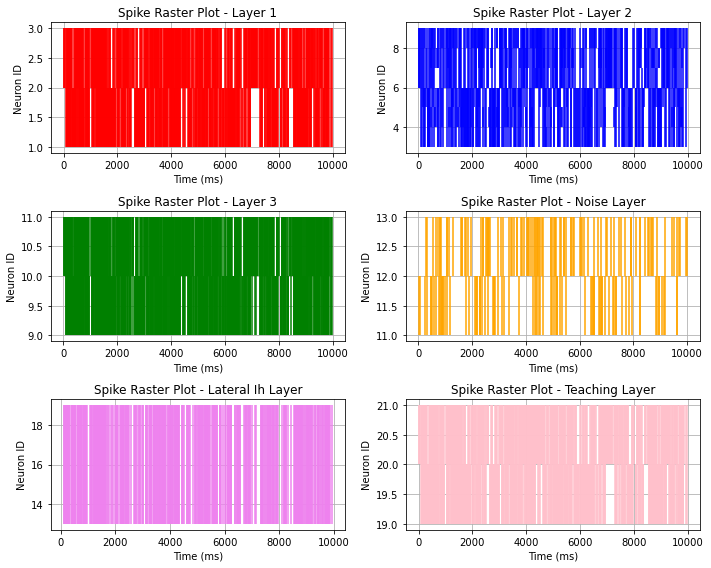

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import os
import nest


def purpura_distance(spiketrain1, spiketrain2, cost):
    """
    spiketrain1 and spiketrain2 are vectors containing the spike times of two spike trains.
    cost is a parameter that determines the sensitivity of the distance calculation to the time differences between
    spikes.
    The function calculates the Victor-Purpura distance by iterating over the spike times of the two spike trains and
    summing exponential terms based on the time differences.
    The result is the Victor-Purpura distance, a measure of the dissimilarity between the spike trains.

    Parameters:
        spiketrain1 (array-like): Spike times of the first spike train.
        spiketrain2 (array-like): Spike times of the second spike train.
        cost (float): Cost parameter for the distance calculation.

    Returns:
        float: Victor-Purpura distance between the two spike trains.
    """
    # Ensure spiketrains are sorted
    spiketrain1 = np.sort(spiketrain1)
    spiketrain2 = np.sort(spiketrain2)

    # Initialize the Victor-Purpura distance
    distance = 0.0

    # Calculate the Victor-Purpura distance
    i = 0
    j = 0
    while i < len(spiketrain1) and j < len(spiketrain2):
        time_diff = spiketrain1[i] - spiketrain2[j]
        if time_diff > 0:
            distance += np.exp(-time_diff / cost)
            j += 1
        elif time_diff < 0:
            distance += np.exp(time_diff / cost)
            i += 1
        else:
            i += 1
            j += 1

    # Add remaining spikes from longer spike train
    while i < len(spiketrain1):
        distance += np.exp(-(spiketrain1[i] - spiketrain2[-1]) / cost)
        i += 1
    while j < len(spiketrain2):
        distance += np.exp(-(spiketrain1[-1] - spiketrain2[j]) / cost)
        j += 1

    return distance

def rossum_metric(spiketrain1, spiketrain2, tau):
    """
    spiketrain1 and spiketrain2 are vectors containing the spike times of two spike trains.
    tau is a parameter that represents the time constant for the kernel function, which determines the weight of each
    spike time difference.
    The function calculates the van Rossum metric by iterating over all pairs of spike times from the two spike trains
    and summing the exponential decay of their absolute time differences.
    The result is the van Rossum metric, a measure of the similarity between the spike trains.

    Parameters:
        spiketrain1 (array-like): Spike times of the first spike train.
        spiketrain2 (array-like): Spike times of the second spike train.
        tau (float): Time constant for the kernel function.

    Returns:
        float: van Rossum metric between the two spike trains.
    """
    # Ensure spiketrains are sorted
    spiketrain1 = np.sort(spiketrain1)
    spiketrain2 = np.sort(spiketrain2)

    # Initialize the van Rossum distance
    distance = 0.0

    # Calculate the van Rossum metric
    for spike_time1 in spiketrain1:
        for spike_time2 in spiketrain2:
            distance += np.exp(-np.abs(spike_time1 - spike_time2) / tau)

    return distance
def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,
                senders_teaching_layer,ts_teaching_layer):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    # Teaching Layer
    plt.subplot(3, 2, 6)
    plt.title('Spike Raster Plot - Teaching Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_teaching_layer, ts_teaching_layer):
        plt.vlines(spike_time, sender, sender + 1, color='pink')

    plt.tight_layout()
    plt.savefig("snn_architecture_result/snn_LH_trainin-ReSuMe.py_raster_plot.png")
    plt.show()

def save_weights(weights, filename):
    # Ensure the 'results' directory exists
    os.makedirs("snn_architecture_result", exist_ok=True)
    # Save the weights in NPY format

    weights.dump(os.path.join("snn_architecture_result", filename))
def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 2)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 6)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 2)
    noise_layer = nest.Create("poisson_generator", 2)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 6)
    teaching_layer = nest.Create("iaf_psc_alpha", 2)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")
    spike_recorder_teaching = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)
    nest.Connect(teaching_layer, spike_recorder_teaching)


    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_l2l3 = {"synapse_model": "stdp_triplet_synapse", "weight": 280.0, "Wmax":400}
    syn_spec_lnl2 = {"weight": 800.0}
    syn_spec_tll3 = {"weight": 1200.0}
    syn_spec_ihl2 = {"weight": -100.0}
    syn_spec_l3ih = {"weight": 550.0}

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # Connect layer 2 to layer 3 individually
    nest.Connect(neuron_layer2, neuron_layer3, syn_spec=syn_spec_l2l3)



    # Connect teaching layer to layer 3 individually
    nest.Connect(teaching_layer[0], neuron_layer3[0], syn_spec=syn_spec_tll3)
    nest.Connect(teaching_layer[1], neuron_layer3[1], syn_spec=syn_spec_tll3)


    # Connect L3 to Lateral Ih using probabilistic connectivity
    nest.Connect(neuron_layer3, lateral_ih_layer, syn_spec=syn_spec_l3ih)

    # Connect Lateral ih to L2 using ih synapses
    nest.Connect(lateral_ih_layer, neuron_layer2,  syn_spec=syn_spec_ihl2)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})
            nest.SetStatus(teaching_layer[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]
    events_teaching_layer = nest.GetStatus(spike_recorder_teaching, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    senders_teaching_layer = events_teaching_layer["senders"]
    ts_teaching_layer = events_teaching_layer["times"]

    # save final weights
    print("Saving weights ...")
    save_weights(np.asarray(nest.GetStatus(nest.GetConnections(neuron_layer2, neuron_layer3), "weight")),"weights_l2l3.npy")

    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,
                senders_teaching_layer,ts_teaching_layer)


simulate_neural_network(num_steps=200, simulation_duration=50.0, min_current=300.0, max_current=600.0)

**Inference using pre-trained weights**

Loading weights ...
291.95811694473235
287.5965099604822
294.1165364512466
289.05186567290013
294.01336610036003
289.12183647080684
288.1953947370069
294.1621879112137
289.3609182029676
296.1173230167084
289.9695350924345
296.9614331048663
Step 1/20
Step 2/20
Step 3/20
Step 4/20
Step 5/20
Step 6/20
Step 7/20
Step 8/20
Step 9/20
Step 10/20
Step 11/20
Step 12/20
Step 13/20
Step 14/20
Step 15/20
Step 16/20
Step 17/20
Step 18/20
Step 19/20
Step 20/20
Purpura Distance between n0 in Layer 1 and n0 in Layer 3: 10.384672246203257
Purpura Distance between n1 in Layer 1 and n1 in Layer 3: 3.470891101152878
Rossum Metric between n0 in Layer 1 and n0 in Layer 3: 3.2185910183327278
Rossum Metric between n1 in Layer 1 and n1 in Layer 3: 3.457330699577294


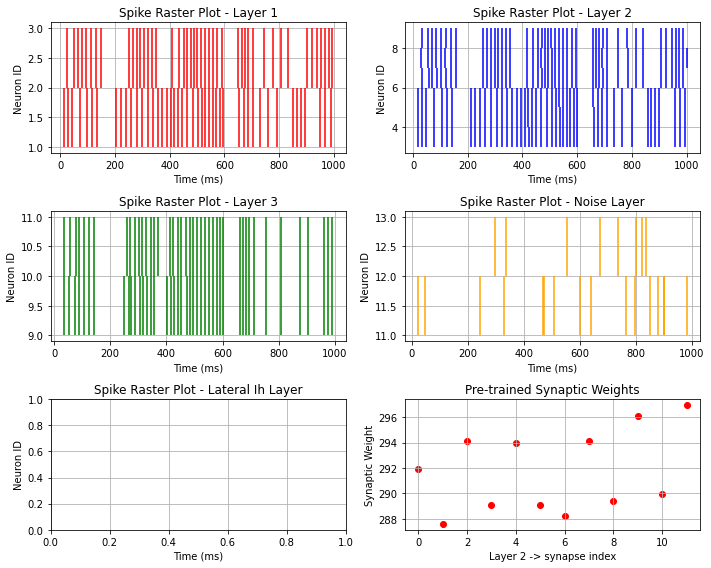

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import os
import nest


def purpura_distance(spiketrain1, spiketrain2, cost):
    """
    spiketrain1 and spiketrain2 are vectors containing the spike times of two spike trains.
    cost is a parameter that determines the sensitivity of the distance calculation to the time differences between
    spikes.
    The function calculates the Victor-Purpura distance by iterating over the spike times of the two spike trains and
    summing exponential terms based on the time differences.
    The result is the Victor-Purpura distance, a measure of the dissimilarity between the spike trains.

    Parameters:
        spiketrain1 (array-like): Spike times of the first spike train.
        spiketrain2 (array-like): Spike times of the second spike train.
        cost (float): Cost parameter for the distance calculation.

    Returns:
        float: Victor-Purpura distance between the two spike trains.
    """
    # Ensure spiketrains are sorted
    spiketrain1 = np.sort(spiketrain1)
    spiketrain2 = np.sort(spiketrain2)

    # Initialize the Victor-Purpura distance
    distance = 0.0

    # Calculate the Victor-Purpura distance
    i = 0
    j = 0
    while i < len(spiketrain1) and j < len(spiketrain2):
        time_diff = spiketrain1[i] - spiketrain2[j]
        if time_diff > 0:
            distance += np.exp(-time_diff / cost)
            j += 1
        elif time_diff < 0:
            distance += np.exp(time_diff / cost)
            i += 1
        else:
            i += 1
            j += 1

    # Add remaining spikes from longer spike train
    while i < len(spiketrain1):
        distance += np.exp(-(spiketrain1[i] - spiketrain2[-1]) / cost)
        i += 1
    while j < len(spiketrain2):
        distance += np.exp(-(spiketrain1[-1] - spiketrain2[j]) / cost)
        j += 1

    return distance

def rossum_metric(spiketrain1, spiketrain2, tau):
    """
    spiketrain1 and spiketrain2 are vectors containing the spike times of two spike trains.
    tau is a parameter that represents the time constant for the kernel function, which determines the weight of each
    spike time difference.
    The function calculates the van Rossum metric by iterating over all pairs of spike times from the two spike trains
    and summing the exponential decay of their absolute time differences.
    The result is the van Rossum metric, a measure of the similarity between the spike trains.

    Parameters:
        spiketrain1 (array-like): Spike times of the first spike train.
        spiketrain2 (array-like): Spike times of the second spike train.
        tau (float): Time constant for the kernel function.

    Returns:
        float: van Rossum metric between the two spike trains.
    """
    # Ensure spiketrains are sorted
    spiketrain1 = np.sort(spiketrain1)
    spiketrain2 = np.sort(spiketrain2)

    # Initialize the van Rossum distance
    distance = 0.0

    # Calculate the van Rossum metric
    for spike_time1 in spiketrain1:
        for spike_time2 in spiketrain2:
            distance += np.exp(-np.abs(spike_time1 - spike_time2) / tau)

    return distance
def raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer, weights):
    plt.figure(figsize=(10, 8))

    # Layer 1
    plt.subplot(3, 2, 1)
    plt.title('Spike Raster Plot - Layer 1')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer1, ts_layer1):
        plt.vlines(spike_time, sender, sender + 1, color='red')

    # Layer 2
    plt.subplot(3, 2, 2)
    plt.title('Spike Raster Plot - Layer 2')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer2, ts_layer2):
        plt.vlines(spike_time, sender, sender + 1, color='blue')

    # Layer 3
    plt.subplot(3, 2, 3)
    plt.title('Spike Raster Plot - Layer 3')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_layer3, ts_layer3):
        plt.vlines(spike_time, sender, sender + 1, color='green')

    # Noise Layer
    plt.subplot(3, 2, 4)
    plt.title('Spike Raster Plot - Noise Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_noise_layer, ts_noise_layer):
        plt.vlines(spike_time, sender, sender + 1, color='orange')

    # Lateral Ih Layer
    plt.subplot(3, 2, 5)
    plt.title('Spike Raster Plot - Lateral Ih Layer')
    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron ID')
    plt.grid()
    for sender, spike_time in zip(senders_lateral_ih_layer, ts_lateral_ih_layer):
        plt.vlines(spike_time, sender, sender + 1, color='violet')

    # STDP weights
    plt.subplot(3, 2, 6)
    plt.scatter(range(len(weights)), weights, label='Layer 2 -> Layer 3', color='red')
    plt.xlabel('Layer 2 -> synapse index')
    plt.ylabel('Synaptic Weight')
    plt.title('Pre-trained Synaptic Weights')
    plt.grid()

    plt.tight_layout()
    plt.savefig("snn_architecture_result/inference_using_pretrained_raster_plot.png")
    plt.show()

def load_weights(filename):
    """
    Load weights from an NPY file.

    Parameters:
        filename (str): The name of the NPY file containing the weights.

    Returns:
        ndarray: The loaded weights.
    """
    # Construct the file path
    file_path = os.path.join("snn_architecture_result", filename)

    # Load the weights from the NPY file
    try:
        weights = np.load(file_path,allow_pickle=True)
        return weights
    except FileNotFoundError:
        print(f"File '{file_path}' not found.")
        return None

def simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0):
    # Reset the NEST simulator
    nest.ResetKernel()
    nest.set_verbosity(20)  # Set NEST verbosity level to 20
    nest.SetKernelStatus({'print_time': False})

    # Create the neurons
    nest.SetDefaults("iaf_psc_alpha", {"I_e": 0.0})
    neuron_layer1 = nest.Create("iaf_psc_alpha", 2)
    neuron_layer2 = nest.Create("iaf_psc_alpha", 6)
    neuron_layer3 = nest.Create("iaf_psc_alpha", 2)
    noise_layer = nest.Create("poisson_generator", 2)
    lateral_ih_layer = nest.Create("iaf_psc_alpha", 6)

    nest.SetStatus(noise_layer, {"rate": 10.0})  # Set the firing rate of the noisy neurons

    # Create spike recorders for each layer
    spike_recorder_layer1 = nest.Create("spike_recorder")
    spike_recorder_layer2 = nest.Create("spike_recorder")
    spike_recorder_layer3 = nest.Create("spike_recorder")
    spike_recorder_noise_layer = nest.Create("spike_recorder")
    spike_recorder_lateral_ih_layer = nest.Create("spike_recorder")

    # Connect the spike recorders to the neurons
    nest.Connect(neuron_layer1, spike_recorder_layer1)
    nest.Connect(neuron_layer2, spike_recorder_layer2)
    nest.Connect(neuron_layer3, spike_recorder_layer3)
    nest.Connect(noise_layer, spike_recorder_noise_layer)
    nest.Connect(lateral_ih_layer, spike_recorder_lateral_ih_layer)


    # Define connectivity between neurons
    syn_spec_l1l2 = {"weight": 1200.0}
    syn_spec_lnl2 = {"weight": 200.0}
    syn_spec_ihl2 = {"weight": -200.0}
    syn_spec_l3ih = {"weight": 550.0}

    # save final weights
    print("Loading weights ...")
    weights_l2l3=load_weights("weights_l2l3.npy")

    # Define the connections for neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    connections_layer1 = [(neuron_layer1[0], neuron_layer2[i]) for i in range(3)]

    # Define the connections for neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    connections_layer2 = [(neuron_layer1[1], neuron_layer2[i]) for i in range(3, 6)]

    # Connect neuron 1 of layer 1 to neurons 1, 2, 3 of layer 2
    for connection in connections_layer1:
        nest.Connect(connection[0], connection[1], syn_spec=syn_spec_l1l2 )

    # Connect neuron 2 of layer 1 to neurons 4, 5, 6 of layer 2
    for connection in connections_layer2:
        nest.Connect(connection[0], connection[1],  syn_spec=syn_spec_l1l2)

    # connect all the neurons in layer 2 to layer 3
    for i in range(len(neuron_layer2)):
        for j in range(len(neuron_layer3)):
            weight_index = i * len(neuron_layer3) + j
            weight = weights_l2l3[weight_index]
            print(weight)
            nest.Connect(neuron_layer2[i], neuron_layer3[j], syn_spec={"weight": weight})



    nest.Connect(neuron_layer2, lateral_ih_layer, syn_spec=syn_spec_ihl2)

    # Connect Lateral L3 to IL using ih synapses
    nest.Connect(neuron_layer3, lateral_ih_layer, syn_spec=syn_spec_l3ih)

    # Define the connections from noisy neurons to layer 2 neurons
    connection_mapping = {0: [1, 4], 1: [2, 5]}

    # Connect the noisy neurons to specific neurons in layer 2
    for noise_neuron, target_neurons in connection_mapping.items():
        for target_neuron in target_neurons:
            nest.Connect(noise_layer[noise_neuron], neuron_layer2[target_neuron], syn_spec=syn_spec_lnl2)


    for step in range(num_steps):
        print(f"Step {step + 1}/{num_steps}")

        # Generate random currents for neurons 1 and 2 in layer 1
        random_currents = np.random.uniform(min_current, max_current, size=2)

        # Apply the random currents to neurons in layer 1
        for i, current in enumerate(random_currents):
            nest.SetStatus(neuron_layer1[i], {"I_e": current})

        # Simulate the network for 50 ms
        nest.Simulate(simulation_duration)

    # Retrieve spike times from spike recorders
    events_layer1 = nest.GetStatus(spike_recorder_layer1, "events")[0]
    events_layer2 = nest.GetStatus(spike_recorder_layer2, "events")[0]
    events_layer3 = nest.GetStatus(spike_recorder_layer3, "events")[0]
    events_noise_layer = nest.GetStatus(spike_recorder_noise_layer, "events")[0]
    events_lateral_ih_layer = nest.GetStatus(spike_recorder_lateral_ih_layer, "events")[0]

    # Extract senders and spike times
    senders_layer1 = events_layer1["senders"]
    ts_layer1 = events_layer1["times"]

    senders_layer2 = events_layer2["senders"]
    ts_layer2 = events_layer2["times"]

    senders_layer3 = events_layer3["senders"]
    ts_layer3 = events_layer3["times"]

    senders_noise_layer = events_noise_layer["senders"]
    ts_noise_layer = events_noise_layer["times"]

    senders_lateral_ih_layer = events_lateral_ih_layer["senders"]
    ts_lateral_ih_layer = events_lateral_ih_layer["times"]

    # Compute the purpura_distance and rossum_metric
    cost = 1.0  # You can adjust this parameter as needed
    tau = 1.0  # You can adjust this parameter as needed

    # Extract spike times for neurons n0 and n1 in Layer 1 and Layer 3
    n0_spikes_layer1 = events_layer1["times"][events_layer1["senders"] == neuron_layer1[0]]
    n1_spikes_layer1 = events_layer1["times"][events_layer1["senders"] == neuron_layer1[1]]
    n0_spikes_layer3 = events_layer3["times"][events_layer3["senders"] == neuron_layer3[0]]
    n1_spikes_layer3 = events_layer3["times"][events_layer3["senders"] == neuron_layer3[1]]

    purpura_distance_n0 = purpura_distance(n0_spikes_layer1, n0_spikes_layer3, cost)
    purpura_distance_n1 = purpura_distance(n1_spikes_layer1, n1_spikes_layer3, cost)

    rossum_metric_n0 = rossum_metric(n0_spikes_layer1, n0_spikes_layer3, tau)
    rossum_metric_n1 = rossum_metric(n1_spikes_layer1, n1_spikes_layer3, tau)

    print("Purpura Distance between n0 in Layer 1 and n0 in Layer 3:", purpura_distance_n0)
    print("Purpura Distance between n1 in Layer 1 and n1 in Layer 3:", purpura_distance_n1)
    print("Rossum Metric between n0 in Layer 1 and n0 in Layer 3:", rossum_metric_n0)
    print("Rossum Metric between n1 in Layer 1 and n1 in Layer 3:", rossum_metric_n1)


    # Call the function with the senders and ts
    raster_plot(senders_layer1, ts_layer1, senders_layer2, ts_layer2, senders_layer3, ts_layer3,
                senders_noise_layer, ts_noise_layer, senders_lateral_ih_layer, ts_lateral_ih_layer,weights_l2l3)


simulate_neural_network(num_steps=20, simulation_duration=50.0, min_current=300.0, max_current=600.0)

## Performance Evaluation on Testing Set: 
Evaluation of the SNN's performance must be conducted on the testing set (encoded signal before exposure of noise).

## MP4 Storage for Reconstructed Video:  
The reconstructed video after training must be saved in an MP4 file

In [33]:
import cv2
import numpy as np
import os

# Path to the folder containing reconstructed frames
frames_folder = 'reconstructedFigures/reconstucted_image'

# Path to the folder where the reconstructed video will be saved
output_folder = 'reconstructed_video'
os.makedirs(output_folder, exist_ok=True)

# Get the list of frames in the folder
frames_list = sorted(os.listdir(frames_folder))

# Load reconstructed audio
reconstructed_audio_path = 'reconstructed_audio/reconstructed_audio.npy'
audio_data = np.load(reconstructed_audio_path, allow_pickle=True)

# Get the dimensions of the first frame to use for video resolution
first_frame_path = os.path.join(frames_folder, frames_list[0])
first_frame = cv2.imread(first_frame_path)
height, width, _ = first_frame.shape

# Specify the codec and create VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Specify the codec
output_video_path = os.path.join(output_folder, 'reconstructed_video.mp4')
out = cv2.VideoWriter(output_video_path, fourcc, 30.0, (width, height))  # Use dimensions of original images

# Iterate over each frame and write it to the video
for frame_file in frames_list:
    frame_path = os.path.join(frames_folder, frame_file)
    frame = cv2.imread(frame_path)
    if frame is not None:
        out.write(frame)

# Release the VideoWriter object
out.release()

print(f"Reconstructed video saved at: {output_video_path}")


Reconstructed video saved at: reconstructed_video/reconstructed_video.mp4


## Results Analysis
Discuss the results

## Conclusions and Future work
Draw the final conclusions and discuss the future work

## Discuss the AI ethics
Discuss the AI ethics implications in terms of security, protection, accountability, and algorithmic bias.